# Week 10: Communication-Efficient Federated Learning

The uplink bill per client is

$$\text{bytes} \;=\; \underbrace{\frac{T}{\tau}}_{\text{how OFTEN you talk}} \;\times\;
\underbrace{|\theta|}_{\text{how MUCH you say}}$$

Week 7's Local SGD (and so FedAvg) shrinks the **first** factor. Every round still ships one
float32 per parameter. Today we shrink the **second** factor by compressing what goes on the
wire. As Week 7 showed, that is the **update** $\Delta_k = \theta_k - \theta^{(r)}$, not
$\theta_k$.

**Why this week is different:** this laptop cannot time a network, but it **can count bytes
exactly**. A byte count depends only on the algorithm and $D$, so it is the same here as on a
phone. That makes the headline number real. It also means the most common mistake,
undercounting your own payload, has nowhere to hide. You will make it on purpose, then fix it.

This is **Lab 8**, the start of spine **Stage 5**: compression on the uplink, Dirichlet
non-IID clients, and client sampling.

## Learning Objectives

By the end of this session, you will be able to:
- Count a client's uplink payload **exactly**, including quantization metadata and sparse
  **indices**, and explain why naive top-$k$ at 10% density saves $5\times$, not $10\times$.
- Implement $b$-bit **uniform quantization**, check it against the theory
  $\frac{R^2}{12(2^b-1)^2}$, and find where that theory breaks.
- Explain why **stochastic rounding** is unbiased, why proofs need that, and what it costs.
- Implement **top-$k$** and **random-$k$**, show which is biased, and test the "energy"
  argument against a control.
- Implement **error feedback (EF)**, show it rescues top-$k$, and explain why it needs
  **stateful clients**.
- Measure how **client sampling** interacts with non-IID data, and find the bias in FedAvg's
  own weights.
- Model **stragglers**: a synchronous round costs the **max** of $K$ client times.
- Build the **Lab 8 deliverable**: an accuracy-vs-bytes **Pareto frontier**.


In [1]:
import math
import time
import functools
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp
from jax.flatten_util import ravel_pytree
import equinox as eqx
import optax

key = jax.random.key(0)
rng = np.random.default_rng(0)

print("jax     ", jax.__version__)
print("equinox ", eqx.__version__)
print("optax   ", optax.__version__)
print("devices :", len(jax.devices()), "x", jax.devices()[0].device_kind)

jax      0.10.2
equinox  0.13.8
optax    0.2.8
devices : 1 x cpu


> **What is real here, and what is simulated.**
>
> - **Real:** every **byte count**. It depends only on the algorithm and $D$, so it matches a
>   phone exactly. So does convergence *per round*. The Lab 8 plot (accuracy vs bytes) needs no
>   hardware disclaimer on its x-axis.
> - **Simulated:** (1) the **model and data**, an 860-parameter CNN on synthetic CIFAR-shaped
>   data. Compression *ratios* transfer, but accuracies do not. (2) **Straggler times** (§7),
>   which are drawn from a LogNormal. (3) **Wall-clock time.** Bytes become seconds only by
>   dividing by a named bandwidth, as in Week 7.


---

## 1. The factor Local SGD never touched

Every client starts round $r$ from the same $\theta^{(r)}$, so the server only needs the
**update** $\Delta_k = \theta_k^{(r,\tau)} - \theta^{(r)}$:

$$\theta^{(r+1)} \;=\; \sum_k p_k \theta_k \;=\; \theta^{(r)} + \sum_k p_k \Delta_k
\;=\; \theta^{(r)} + \bar\Delta$$

(Week 7 showed this equals `optax.sgd(1.0)` on the pseudo-gradient $-\bar\Delta$.) Today we
add one box, a **compression operator** $\mathcal{C}$ on the client:

```
   client k                              server
   --------                              ------
   theta^(r) ---> tau local SGD steps
                        |
                   Delta_k = theta_k - theta^(r)  <- THE object on the wire
                        |
                   C(Delta_k)   <---- TODAY       <- quantize / sparsify / both
                        |  uplink (expensive)
                        +----------------------> sum_k p_k C(Delta_k) = Delta_bar
                                                          |
                                                  theta^(r+1) = theta^(r) + Delta_bar
   theta^(r+1) <------------------------------------------+
                downlink: dense float32, NOT compressed
```

### Which of the four states goes on the wire?

| state | size here | uploaded? | why |
|---|---|---|---|
| **model parameters** ($\Delta_k$) | $D = 860$ floats | **yes, the payload** | the server aggregates it |
| **batch statistics** | 34 floats | *policy choice* | averaging them is debated (FedBN, Week 11). We send them uncompressed and count them |
| **optimizer state** | 0 (plain SGD) | **no** | stays on the client. Under Adam it would be $2D$, and it would still stay home |
| **PRNG state** | 1 key | **no** | a seed, not data |

Only one state is a payload. Because we kept the four states separate since Week 3, we can
compress exactly that one. One merged blob would force us to special-case it.

### Why compress the uplink, not the downlink?

1. **Links are asymmetric.** A phone's uplink is often $5$–$10\times$ slower than its downlink.
2. **The math is asymmetric.** The downlink is one broadcast that everyone starts from.
   Corrupting it breaks the shared starting point. The uplink is $K$ separate $\Delta_k$'s,
   and compressing one only perturbs its share of an average.

**Everything today is uplink only.** Say so whenever you quote a ratio.


### The codebase, carried forward

This is the same Equinox CNN, synthetic data, and Optax SGD as Weeks 7 and 9. The model is
tiny on purpose. Bytes and rounds are exact at any scale.

New tool: `jax.flatten_util.ravel_pytree` flattens the parameter PyTree into **one 1-D
vector**. Every compressor below is then a function $\mathbb{R}^D \to \mathbb{R}^D$ plus a
byte count.


In [2]:
IMG, N_CLASSES = 32, 4

class SmallCNN(eqx.Module):
    conv1: eqx.nn.Conv2d
    bn1: eqx.nn.BatchNorm
    conv2: eqx.nn.Conv2d
    bn2: eqx.nn.BatchNorm
    head: eqx.nn.Linear

    def __init__(self, key, c=8, n_classes=N_CLASSES):
        k1, k2, k3 = jax.random.split(key, 3)
        self.conv1 = eqx.nn.Conv2d(3, c, 3, stride=2, padding=1, use_bias=False, key=k1)
        self.bn1 = eqx.nn.BatchNorm(c, axis_name="batch", mode="batch", momentum=0.9)
        self.conv2 = eqx.nn.Conv2d(c, c, 3, stride=2, padding=1, use_bias=False, key=k2)
        self.bn2 = eqx.nn.BatchNorm(c, axis_name="batch", mode="batch", momentum=0.9)
        self.head = eqx.nn.Linear(c, n_classes, key=k3)

    def __call__(self, x, state):
        h, state = self.bn1(self.conv1(x), state)
        h = jax.nn.relu(h)
        h, state = self.bn2(self.conv2(h), state)
        h = jax.nn.relu(h)
        h = jnp.mean(h, axis=(1, 2))
        return self.head(h), state


def batched_forward(model, state, x):
    return eqx.filter_vmap(lambda m, s, xi: m(xi, s), in_axes=(None, None, 0),
                           out_axes=(0, None), axis_name="batch")(model, state, x)

def loss_fn(model, state, x, y):
    logits, state = batched_forward(model, state, x)
    return optax.softmax_cross_entropy_with_integer_labels(logits, y).mean(), state


# ---- The four states, still explicitly apart ----
model0, bn0 = eqx.nn.make_with_state(SmallCNN)(jax.random.key(0))
params0, static0 = eqx.partition(model0, eqx.is_inexact_array)

LR = 0.1
optimizer = optax.sgd(LR)
opt0 = optimizer.init(params0)

# The Week-4 tool this lab is built on: the parameter tree AS A VECTOR.
flat0, unravel = ravel_pytree(params0)
D_PARAMS = int(flat0.size)
PARAM_BYTES = D_PARAMS * 4
BN_VALUES = sum(int(l.size) for l in jax.tree.leaves(bn0))

print(f"parameters   : {D_PARAMS:,}  ->  ravel_pytree gives one vector of shape {flat0.shape}")
print(f"payload      : {PARAM_BYTES:,} bytes/round/client at dense float32  <- the number to beat")
print(f"batch stats  : {BN_VALUES} values ({BN_VALUES * 4} bytes) -- a SEPARATE state, uploaded uncompressed")
print(f"opt state    : {sum(int(l.size) for l in jax.tree.leaves(opt0))} values (plain SGD) -- NEVER uploaded")
print(f"\nround-trips exactly: {bool(jnp.allclose(ravel_pytree(unravel(flat0))[0], flat0))}")

parameters   : 860  ->  ravel_pytree gives one vector of shape (860,)
payload      : 3,440 bytes/round/client at dense float32  <- the number to beat
batch stats  : 34 values (136 bytes) -- a SEPARATE state, uploaded uncompressed
opt state    : 0 values (plain SGD) -- NEVER uploaded

round-trips exactly: True


In [3]:
# ---------------- Synthetic CIFAR-shaped data (no network in the harness) ----------------
# The labels must be LEARNABLE. Otherwise every scheme scores chance and the Pareto plot
# is flat, so compression's accuracy cost would be invisible.
NOISE = 3.0

def make_templates(key):
    lo = jax.random.normal(key, (N_CLASSES, 3, 8, 8))
    return jax.image.resize(lo, (N_CLASSES, 3, IMG, IMG), method="linear")

TEMPLATES = make_templates(jax.random.key(7))

def make_data(n, key, noise=NOISE):
    kl, kn = jax.random.split(key)
    labels = jax.random.randint(kl, (n,), 0, N_CLASSES)
    return TEMPLATES[labels] + jax.random.normal(kn, (n, 3, IMG, IMG)) * noise, labels

X_all, Y_all = make_data(4096, jax.random.key(1))
X_te, Y_te = make_data(1024, jax.random.key(2))

@eqx.filter_jit
def evaluate(params, bn, x, y):
    logits, _ = batched_forward(eqx.combine(params, static0), bn, x)
    l = optax.softmax_cross_entropy_with_integer_labels(logits, y).mean()
    return l, jnp.mean(jnp.argmax(logits, -1) == y)

l0, a0 = evaluate(params0, bn0, X_te, Y_te)
print(f"train {X_all.shape}  test {X_te.shape}  |  {N_CLASSES} classes, noise sigma = {NOISE}")
print(f"at init: test loss {float(l0):.4f}  acc {float(a0):.3f}  (chance = {1 / N_CLASSES:.3f})")
print("\n(The real Lab 8 uses CIFAR-10 via Grain on the GPU node.")
print(" Compression ratios transfer unchanged; accuracies do not.)")

train (4096, 3, 32, 32)  test (1024, 3, 32, 32)  |  4 classes, noise sigma = 3.0
at init: test loss 1.4148  acc 0.252  (chance = 0.250)

(The real Lab 8 uses CIFAR-10 via Grain on the GPU node.
 Compression ratios transfer unchanged; accuracies do not.)


In [4]:
# ---------------- Local training: scan over tau, vmap over clients (Week 7's Stage 3) -----
def local_step(carry, batch):
    params, bn, opt_state = carry
    x, y = batch
    (loss, bn_new), grads = jax.value_and_grad(
        lambda p, s: loss_fn(eqx.combine(p, static0), s, x, y), has_aux=True)(params, bn)
    updates, opt_new = optimizer.update(grads, opt_state, params)
    return (eqx.apply_updates(params, updates), bn_new, opt_new), loss


def local_block(params, bn, opt_state, xs, ys):
    # tau local steps for ONE client. Trip count = leading axis of xs (Week 4).
    (p, b, o), losses = jax.lax.scan(local_step, (params, bn, opt_state), (xs, ys))
    return p, b, jnp.mean(losses)


run_clients = eqx.filter_jit(jax.vmap(local_block, in_axes=(0, 0, 0, 0, 0)))

def broadcast(tree, n):
    return jax.tree.map(lambda a: jnp.broadcast_to(a, (n,) + a.shape), tree)

def aggregate(client_tree, p):
    return jax.tree.map(lambda leaf: jnp.tensordot(p, leaf, axes=1), client_tree)

# Flatten each client's tree into a (K, D) matrix -- ravel_pytree is vmappable.
flatten_clients = jax.jit(jax.vmap(lambda t: ravel_pytree(t)[0]))

print("local_block   : scan over tau local steps")
print("run_clients   : vmap of local_block over K clients")
print("flatten_clients: (K, ...) parameter tree -> (K, D) matrix  <- where compression lives")

local_block   : scan over tau local steps
run_clients   : vmap of local_block over K clients
flatten_clients: (K, ...) parameter tree -> (K, D) matrix  <- where compression lives


### The clients: Dirichlet non-IID (Stage 5 begins)

The default partition is now **Dirichlet** (Yurochkin et al., 2019; Wang et al., 2020). For
each class $c$, draw $\mathbf{p}_c \sim \text{Dir}(\alpha \mathbf{1}_K)$ and split that class
across clients in those proportions. $\alpha \to \infty$ gives IID data, and $\alpha \to 0$
gives one class per client. We use **a single draw** (seed 3) with **no** `min_size`
resample guard, so client 4 ends up with only 46 examples.

The IID partition stays as a **control** for §6.


In [5]:
K_CLIENTS = 5
B_LOCAL = 32
ALPHA = 0.5

def iid_partition(n, K, seed=0):
    return np.array_split(np.random.default_rng(seed).permutation(n), K)

def dirichlet_partition(Y, K, alpha, seed=0):
    # Yurochkin et al. (2019) / Wang et al. (2020), class-major form: per class, split across clients in Dirichlet proportions.
    r = np.random.default_rng(seed)
    Yn = np.asarray(Y)
    shards = [[] for _ in range(K)]
    for c in range(N_CLASSES):
        idx = np.where(Yn == c)[0]
        r.shuffle(idx)
        prop = r.dirichlet(np.repeat(alpha, K))
        cuts = (np.cumsum(prop) * len(idx)).astype(int)[:-1]
        for k, part in enumerate(np.split(idx, cuts)):
            shards[k].extend(part.tolist())
    return [np.array(sorted(s)) for s in shards]


shards_iid = iid_partition(len(X_all), K_CLIENTS, seed=0)
shards_nid = dirichlet_partition(Y_all, K_CLIENTS, ALPHA, seed=3)

print(f"K = {K_CLIENTS} clients, local batch {B_LOCAL}, Dirichlet alpha = {ALPHA}")
print(f"{'client':>7}  {'n_k':>6}  {'share':>7}  {'label counts':>26}")
print("-" * 54)
for k, s in enumerate(shards_nid):
    cnt = np.bincount(np.asarray(Y_all)[s], minlength=N_CLASSES)
    print(f"{k:>7}  {len(s):>6}  {len(s) / len(X_all):>6.1%}  {str(cnt):>26}")
print(f"\nsize imbalance: largest / smallest = "
      f"{max(len(s) for s in shards_nid) / min(len(s) for s in shards_nid):.1f}x")
print(f"IID control shard sizes: {[len(s) for s in shards_iid]}")
print("\n(5 clients here so the notebook stays fast. The real Lab 8 runs 100 clients on")
print(" the GPU node, where client sampling (Section 6) really matters.)")

K = 5 clients, local batch 32, Dirichlet alpha = 0.5
 client     n_k    share                label counts
------------------------------------------------------
      0     137    3.3%               [ 0 37  1 99]
      1     868   21.2%           [169 503   4 192]
      2    1487   36.3%           [651 456   8 372]
      3    1558   38.0%       [ 194    2 1005  357]
      4      46    1.1%               [ 5 11 12 18]

size imbalance: largest / smallest = 33.9x
IID control shard sizes: [820, 819, 819, 819, 819]

(5 clients here so the notebook stays fast. The real Lab 8 runs 100 clients on
 the GPU node, where client sampling (Section 6) really matters.)


In [6]:
def sample_batches(shards, tau, rnd, B=B_LOCAL):
    xs, ys = [], []
    Xh, Yh = np.asarray(X_all), np.asarray(Y_all)
    for k, sh in enumerate(shards):
        r = np.random.default_rng(1000 * rnd + k)
        pick = r.choice(sh, size=(tau, B), replace=True)
        xs.append(Xh[pick]); ys.append(Yh[pick])
    return jnp.asarray(np.stack(xs)), jnp.asarray(np.stack(ys))


def one_round_deltas(server_p, server_b, shards, tau, rnd):
    # Run one FedAvg round's local work and return the (K, D) matrix of client updates.
    K = len(shards)
    wp, wb, wo = broadcast(server_p, K), broadcast(server_b, K), broadcast(opt0, K)
    xs, ys = sample_batches(shards, tau, rnd)
    cp, cb, _ = run_clients(wp, wb, wo, xs, ys)
    deltas = jax.tree.map(lambda c, s: c - s[None], cp, server_p)
    return flatten_clients(deltas), cb


TAU = 8
D_mat, _ = one_round_deltas(params0, bn0, shards_nid, TAU, 0)

theta_norm = float(jnp.linalg.norm(flat0))
delta_norms = [float(jnp.linalg.norm(D_mat[k])) for k in range(K_CLIENTS)]

print(f"one round, tau = {TAU}: the (K, D) matrix of client updates -> {D_mat.shape}")
print()
print(f"||theta^(r)||        = {theta_norm:>8.4f}   <- what a naive design would ship")
print(f"||Delta_k|| (mean)   = {np.mean(delta_norms):>8.4f}   <- what we actually ship "
      f"({theta_norm / np.mean(delta_norms):.0f}x smaller in norm)")
print(f"||Delta_bar||        = {float(jnp.linalg.norm(jnp.mean(D_mat, axis=0))):>8.4f}")
print()
print(f"Bytes, though, are IDENTICAL: both are {D_PARAMS:,} float32 = {PARAM_BYTES:,} bytes.")
print("A smaller NORM is not a smaller PAYLOAD. A small Delta is easier to QUANTIZE")
print("(a narrow range needs fewer levels), but that is not a saving by itself.")

one round, tau = 8: the (K, D) matrix of client updates -> (5, 860)

||theta^(r)||        =   4.7162   <- what a naive design would ship
||Delta_k|| (mean)   =   0.4358   <- what we actually ship (11x smaller in norm)
||Delta_bar||        =   0.2411

Bytes, though, are IDENTICAL: both are 860 float32 = 3,440 bytes.
A smaller NORM is not a smaller PAYLOAD. A small Delta is easier to QUANTIZE
(a narrow range needs fewer levels), but that is not a saving by itself.


> **Observe:** $\Delta_k$ is $\sim 11\times$ smaller **in norm** than $\theta$, yet it costs
> **exactly the same bytes**: 860 float32 = 3,440 B. A small norm is not a small payload.
> Local SGD cut *how often* we send, but *how much* we send per round is unchanged since
> Week 5. The rest of this lab closes that gap.


### The map: what a compression operator can be

Two questions sort every scheme in this notebook.

**1. Is it unbiased?** $\mathbb{E}[\mathcal{C}(v)] = v$. Convergence proofs need this. An
unbiased operator with bounded variance acts like **extra gradient noise**, which SGD already
handles. A **biased** operator can push the same way every round, and that drift does not
average out. §5 fixes this.

**2. What gets cheaper?** **Quantization** keeps every coordinate but uses fewer **bits** per
coordinate. **Sparsification** keeps full precision but sends fewer **coordinates**. The two
combine (§9).

| scheme | bits/element (density $d$, $b$ bits) | unbiased? | client state? | cost |
|---|---|---|---|---|
| dense float32 | 32 | yes (exact) | no | none (baseline) |
| **$b$-bit quant**, deterministic | $b$ (+metadata) | **no** | no | rounding bias |
| **$b$-bit quant**, stochastic (QSGD) | $b$ (+metadata) | **yes** | no | ~2× the MSE |
| **sign SGD** | $1$ (+scale) | **no** | no | loses all magnitude |
| **top-$k$** | $32d$ + **index cost** | **no** | no | drops small coords forever |
| **random-$k$** (rescaled $1/d$) | $32d$ + **index cost** | **yes** | no | huge variance at small $d$ |
| **top-$k$ + error feedback** | $32d$ + **index cost** | no, but repaid over time | **yes, $O(D)$** | memory; phones may not have it |
| **top-$k$ + $b$-bit + bitmap** | $bd + 1$ | no | optional | the combination (§9) |

Note the **index cost** column. People forget it, and §2 is about it.


---

## 2. Counting bytes exactly — and the cost everyone forgets

Build the meter first. **A compression result is a byte count. A wrong byte count is a wrong
result.**

- **Dense float32:** $4D$ bytes. This is the baseline.
- **$b$-bit quantization:** $Db/8$ bytes, **plus metadata**. The receiver needs
  $(\text{lo}, \text{scale})$, which adds 8 bytes. That is tiny at $D = 860$, but it is paid
  **per block** if you quantize per layer or per block.
- **Sparsification, the trap.** *"Top-$k$ at 10% sends 10% of coordinates, so it saves
  $10\times$."* **Wrong.** A sparse vector is a list of **(index, value)** pairs, and the
  receiver must be told *which* slots are filled:

$$\text{bytes}_{\text{naive top-}k} \;=\; \underbrace{4dD}_{\text{float32 values}}
\;+\; \underbrace{4dD}_{\text{int32 indices}} \;=\; 8dD$$

  At $d = 0.1$ that is $0.8D$ vs $4D$: **$5\times$, not $10\times$**. Half the payload says
  *where*, not *what*.

The indices can be encoded more cheaply:

- **int32:** $4dD$ bytes. Simple, but bad at high density.
- **Bitmap:** 1 bit per coordinate, so **$D/8$ bytes for any $d$**. It beats int32 when
  $d > 1/32$.
- **Delta + varint:** sort the indices and store the *gaps*. Most gaps fit in 1 byte. This is
  best at low density.

**The floor.** Picking $k$ of $D$ coordinates is one choice out of $\binom{D}{k}$, so no
encoding can beat

$$\text{index bits} \;\ge\; \log_2 \binom{D}{k} \;\approx\; D \cdot H_2(d),
\qquad H_2(d) = -d\log_2 d - (1-d)\log_2(1-d)$$

Judge an encoder against this floor. Below, we implement all of these and **measure** them.


In [7]:
def bytes_dense(D, dtype_bytes=4):
    return float(D * dtype_bytes)

def bytes_quantized(D, bits, n_blocks=1):
    # D values at `bits` each, plus (lo, scale) as float32 PER BLOCK. Metadata is not free.
    return D * bits / 8.0 + 8.0 * n_blocks

def varint_len(x):
    # LEB128: 7 payload bits per byte.
    n = 1
    while x >= 128:
        x >>= 7
        n += 1
    return n

def bytes_indices(idx_sorted, D, scheme):
    k = len(idx_sorted)
    if scheme == "int32":
        return 4.0 * k
    if scheme == "bitmap":
        return D / 8.0
    if scheme == "varint":
        # GAPS between sorted indices, LEB128-encoded. Measured, not modelled.
        gaps = np.diff(np.concatenate([[-1], np.asarray(idx_sorted)])) - 1
        return float(sum(varint_len(int(g)) for g in gaps))
    raise ValueError(scheme)

def index_entropy_bytes(D, k):
    # log2(C(D, k)) bits: the information-theoretic floor for naming a k-subset of D.
    if k <= 0 or k >= D:
        return 0.0
    bits = (math.lgamma(D + 1) - math.lgamma(k + 1) - math.lgamma(D - k + 1)) / math.log(2.0)
    return bits / 8.0


# Sanity-check the varint encoder against hand arithmetic before trusting it.
print("varint_len: ", [(x, varint_len(x)) for x in [0, 127, 128, 16383, 16384]])
print("            ^ 7 payload bits per byte, so 128 needs 2 bytes")
print()
d_demo, D_demo = 0.1, D_PARAMS
k_demo = int(d_demo * D_demo)
idx_demo = np.sort(np.random.default_rng(0).choice(D_demo, k_demo, replace=False))
print(f"D = {D_demo:,}, density d = {d_demo}, k = {k_demo}")
print(f"{'index encoding':>22}  {'bytes':>9}  {'bytes/coord':>12}  {'bits/coord':>11}  {'vs floor':>9}")
print("-" * 70)
floor_b = index_entropy_bytes(D_demo, k_demo)
for sch in ["int32", "bitmap", "varint"]:
    b = bytes_indices(idx_demo, D_demo, sch)
    print(f"{sch:>22}  {b:>9.1f}  {b / D_demo:>12.4f}  {8 * b / D_demo:>11.4f}  {b / floor_b:>8.2f}x")
print(f"{'entropy floor':>22}  {floor_b:>9.1f}  {floor_b / D_demo:>12.4f}  "
      f"{8 * floor_b / D_demo:>11.4f}  {1.0:>8.2f}x")
print(f"\n{'':>22}  (floor = log2(C(D,k)) -- no encoder can beat this)")

varint_len:  [(0, 1), (127, 1), (128, 2), (16383, 2), (16384, 3)]
            ^ 7 payload bits per byte, so 128 needs 2 bytes

D = 860, density d = 0.1, k = 86
        index encoding      bytes   bytes/coord   bits/coord   vs floor
----------------------------------------------------------------------
                 int32      344.0        0.4000       3.2000      6.90x
                bitmap      107.5        0.1250       1.0000      2.16x
                varint       86.0        0.1000       0.8000      1.72x
         entropy floor       49.9        0.0580       0.4638      1.00x

                        (floor = log2(C(D,k)) -- no encoder can beat this)


In [8]:
# THE TABLE THE LAB IS ABOUT: what does a client actually upload?
print(f"Uplink payload per client per round.  D = {D_PARAMS:,} parameters.")
print(f"{'scheme':>34}  {'bytes':>9}  {'B/elem':>8}  {'vs float32':>11}")
print("-" * 68)

rows = []
def row(name, b):
    rows.append((name, b))
    print(f"{name:>34}  {b:>9.1f}  {b / D_PARAMS:>8.3f}  {PARAM_BYTES / b:>10.1f}x")

row("dense float32 (baseline)", bytes_dense(D_PARAMS))
row("dense float16", bytes_dense(D_PARAMS, 2))
row("8-bit quantized", bytes_quantized(D_PARAMS, 8))
row("4-bit quantized", bytes_quantized(D_PARAMS, 4))
row("1-bit (signSGD)", bytes_quantized(D_PARAMS, 1))

k10 = int(0.1 * D_PARAMS)
idx10 = np.sort(np.random.default_rng(0).choice(D_PARAMS, k10, replace=False))
row("top-k d=0.1, f32 vals + int32 idx",
    4.0 * k10 + bytes_indices(idx10, D_PARAMS, "int32"))
row("top-k d=0.1, f32 vals + bitmap",
    4.0 * k10 + bytes_indices(idx10, D_PARAMS, "bitmap"))
row("top-k d=0.1, 8-bit vals + bitmap",
    1.0 * k10 + bytes_indices(idx10, D_PARAMS, "bitmap") + 8.0)

k01 = int(0.01 * D_PARAMS)
idx01 = np.sort(np.random.default_rng(0).choice(D_PARAMS, k01, replace=False))
row("top-k d=0.01, f32 vals + int32 idx",
    4.0 * k01 + bytes_indices(idx01, D_PARAMS, "int32"))
row("top-k d=0.01, 8-bit vals + varint",
    1.0 * k01 + bytes_indices(idx01, D_PARAMS, "varint") + 8.0)

naive = 4.0 * k10                      # the WRONG answer: values only
honest = 4.0 * k10 + 4.0 * k10         # the right one
print()
print(f"THE TRAP, in one line. top-k at d = 0.1:")
print(f"  'we send 10% of the coordinates'   -> {naive:>8.1f} bytes -> "
      f"{PARAM_BYTES / naive:>4.1f}x  <- WRONG: values only, indices free")
print(f"  a sparse vector is (index, value)  -> {honest:>8.1f} bytes -> "
      f"{PARAM_BYTES / honest:>4.1f}x  <- RIGHT")
print(f"\nHalf the payload says WHERE, not WHAT.")
print(f"Better index encoding wins it back: bitmap + 8-bit values gives "
      f"{PARAM_BYTES / (1.0 * k10 + D_PARAMS / 8.0 + 8.0):.1f}x.")

Uplink payload per client per round.  D = 860 parameters.
                            scheme      bytes    B/elem   vs float32
--------------------------------------------------------------------
          dense float32 (baseline)     3440.0     4.000         1.0x
                     dense float16     1720.0     2.000         2.0x
                   8-bit quantized      868.0     1.009         4.0x
                   4-bit quantized      438.0     0.509         7.9x
                   1-bit (signSGD)      115.5     0.134        29.8x
 top-k d=0.1, f32 vals + int32 idx      688.0     0.800         5.0x
    top-k d=0.1, f32 vals + bitmap      451.5     0.525         7.6x
  top-k d=0.1, 8-bit vals + bitmap      201.5     0.234        17.1x
top-k d=0.01, f32 vals + int32 idx       64.0     0.074        53.8x
 top-k d=0.01, 8-bit vals + varint       27.0     0.031       127.4x

THE TRAP, in one line. top-k at d = 0.1:
  'we send 10% of the coordinates'   ->    344.0 bytes -> 10.0x  <- WRON

at d = 0.1 : int32 0.4000  bitmap 0.1250  varint 0.1000  floor 0.0580 bytes/coord
at d = 0.001: int32 0.0047  bitmap 0.1250  varint 0.0023  floor 0.0014 bytes/coord

bitmap is flat in d (it is always D/8); int32 and varint scale with k.
bitmap beats int32 above d = 1/32 = 0.0312 (where 4dD = D/8).


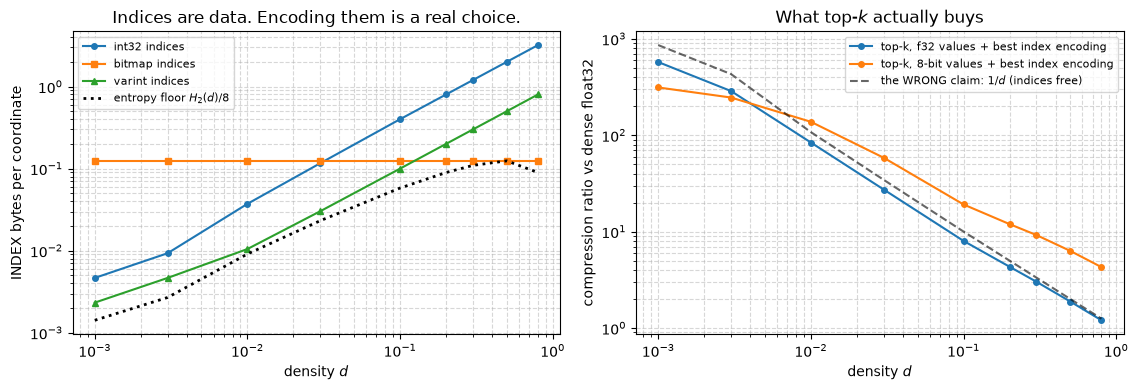

In [9]:
# How the index encodings trade off across density -- the crossover is the point.
densities = np.array([0.001, 0.003, 0.01, 0.03, 0.1, 0.2, 0.3, 0.5, 0.8])
rg = np.random.default_rng(1)

enc = {s: [] for s in ["int32", "bitmap", "varint", "floor"]}
for d in densities:
    k = max(1, int(d * D_PARAMS))
    idx = np.sort(rg.choice(D_PARAMS, k, replace=False))
    for s in ["int32", "bitmap", "varint"]:
        enc[s].append(bytes_indices(idx, D_PARAMS, s) / D_PARAMS)
    enc["floor"].append(index_entropy_bytes(D_PARAMS, k) / D_PARAMS)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))

for s, style in [("int32", "o-"), ("bitmap", "s-"), ("varint", "^-")]:
    ax[0].loglog(densities, enc[s], style, ms=4, label=f"{s} indices")
ax[0].loglog(densities, enc["floor"], "k:", lw=2, label=r"entropy floor $H_2(d)/8$")
ax[0].set_xlabel("density $d$")
ax[0].set_ylabel("INDEX bytes per coordinate")
ax[0].set_title("Indices are data. Encoding them is a real choice.")
ax[0].legend(fontsize=8)
ax[0].grid(True, ls="--", alpha=0.5, which="both")

# total payload (values + indices), best encoder, vs dense
for vb, lab in [(4.0, "f32 values"), (1.0, "8-bit values")]:
    tot = []
    for i, d in enumerate(densities):
        k = max(1, int(d * D_PARAMS))
        best = min(enc["int32"][i], enc["bitmap"][i], enc["varint"][i]) * D_PARAMS
        tot.append(PARAM_BYTES / (vb * k + best + (8.0 if vb == 1.0 else 0.0)))
    ax[1].loglog(densities, tot, "o-", ms=4, label=f"top-k, {lab} + best index encoding")
naive_ratio = [PARAM_BYTES / (4.0 * max(1, int(d * D_PARAMS))) for d in densities]
ax[1].loglog(densities, naive_ratio, "k--", alpha=0.6, label="the WRONG claim: $1/d$ (indices free)")
ax[1].set_xlabel("density $d$")
ax[1].set_ylabel("compression ratio vs dense float32")
ax[1].set_title("What top-$k$ actually buys")
ax[1].legend(fontsize=8)
ax[1].grid(True, ls="--", alpha=0.5, which="both")

plt.tight_layout()

i10 = int(np.where(densities == 0.1)[0][0])
print(f"at d = 0.1 : int32 {enc['int32'][i10]:.4f}  bitmap {enc['bitmap'][i10]:.4f}  "
      f"varint {enc['varint'][i10]:.4f}  floor {enc['floor'][i10]:.4f} bytes/coord")
i001 = int(np.where(densities == 0.001)[0][0])
print(f"at d = 0.001: int32 {enc['int32'][i001]:.4f}  bitmap {enc['bitmap'][i001]:.4f}  "
      f"varint {enc['varint'][i001]:.4f}  floor {enc['floor'][i001]:.4f} bytes/coord")
print(f"\nbitmap is flat in d (it is always D/8); int32 and varint scale with k.")
print(f"bitmap beats int32 above d = 1/32 = {1/32:.4f} (where 4dD = D/8).")

> **Observe:**
>
> 1. **Naive top-$k$ at $d=0.1$ saves $5\times$, not $10\times$.** The int32 indices cost as
>    much as the float32 values. Any claim of $1/d$ has priced the indices at zero. That claim
>    is the dashed line in the right panel.
> 2. **Better index encoding wins it back.** A bitmap ($D/8$, flat in $d$) beats int32 above
>    $d = 1/32$, and varint wins below that. Bitmap + 8-bit values at $d=0.1$ gives a real
>    **$17\times$**, better than the naive $10\times$ that never existed.
> 3. **Our encoders are near the floor.** Varint is **1.6×** above $\log_2\binom{D}{k}$ at
>    $d=0.001$. At $d=0.1$, bitmap is **2.2×** above it and varint **1.7×**.
>
> No accuracy yet, only counting. Every ratio from §3 on divides by these numbers.


### 🔬 Exercise 1

**Price a real model.** Federated fine-tuning of BERT-base (110M parameters) on phones with a
5 Mb/s uplink (0.625 MB/s, from Week 7's table).

1. How long does **one round** of dense float32 upload take? Is FedAvg viable?
2. Compute payload and upload time for: float16, 8-bit, top-$k$ $d=0.01$ with int32 indices,
   and top-$k$ $d=0.01$ with 8-bit values + varint indices.
3. **LoRA** (Week 15) makes $\Delta$ low-rank: rank-8 adapters, ~0.3M parameters. Where does
   it land?
4. Which options get a round under **10 s**? What does that say about the claim
   "communication-efficient FL is solved"?


In [10]:
# --- Reference solution (instructor: blank this out for students) ---

D_BERT = 110_000_000
BW_UP = 0.625e6                       # 5 Mb/s phone uplink, bytes/sec (Week 7's LINKS table)

def upload_time(nbytes):
    return nbytes / BW_UP

# (1)
dense_b = bytes_dense(D_BERT)
print(f"BERT-base: {D_BERT:,} params -> dense float32 = {dense_b / 1e6:.0f} MB per client per round")
print(f"  upload time on a 5 Mb/s uplink: {upload_time(dense_b):.0f} s = "
      f"{upload_time(dense_b) / 60:.1f} min PER ROUND")
print(f"  at 200 rounds that is {200 * upload_time(dense_b) / 3600:.0f} HOURS of uplink per client.")
print(f"  -> Dense FedAvg on BERT over phones is not slow. It is not viable.\n")

# (2) and (3)
k_bert = int(0.01 * D_BERT)
idx_b = np.sort(np.random.default_rng(0).choice(D_BERT, min(k_bert, 200_000), replace=False))
# Measure varint bytes/index on a 200k-index sample at the same density, then scale to k.
# Only the gap statistics matter, not the count.
vb_per_idx = bytes_indices(idx_b, int(D_BERT * len(idx_b) / k_bert), "varint") / len(idx_b)

schemes = [
    ("dense float32",                    dense_b),
    ("dense float16",                    bytes_dense(D_BERT, 2)),
    ("8-bit quantized",                  bytes_quantized(D_BERT, 8)),
    ("top-k d=0.01, f32 + int32 idx",    4.0 * k_bert + 4.0 * k_bert),
    ("top-k d=0.01, 8-bit + varint idx", 1.0 * k_bert + vb_per_idx * k_bert + 8.0),
    ("LoRA r=8 (~0.3M params, f32)",     bytes_dense(300_000)),
    ("LoRA r=8 + 8-bit quantization",    bytes_quantized(300_000, 8)),
]
print(f"{'scheme':>34}  {'MB':>8}  {'upload (s)':>11}  {'vs dense':>9}  {'< 10 s?':>8}")
print("-" * 78)
for name, b in schemes:
    t = upload_time(b)
    print(f"{name:>34}  {b / 1e6:>8.2f}  {t:>11.1f}  {dense_b / b:>8.0f}x  "
          f"{'YES' if t < 10 else 'no':>8}")

# (4)
t_best_comp = upload_time(1.0 * k_bert + vb_per_idx * k_bert + 8.0)
print()
print(f"(4) Three of the seven rows clear 10 s. Which three is the lesson.")
print()
print(f"    Compression alone just makes it, and only by stacking every trick: top-k at 1%")
print(f"    + 8-bit values + varint indices = {t_best_comp:.1f} s. Drop one and you miss: with int32")
print(f"    indices the same density takes {upload_time(4.0 * k_bert + 4.0 * k_bert):.1f} s (3x worse), purely from")
print(f"    Section 2's index cost. And d=0.01 needs error feedback (Section 5), so this")
print(f"    option also requires stateful clients.")
print()
print("    LoRA gets there easily by CHANGING D: only ~300k numbers to send,")
print(f"    {upload_time(bytes_dense(300_000)):.1f} s uncompressed and {upload_time(bytes_quantized(300_000, 8)):.1f} s with 8-bit."
      " Communication scales with rank, not model size.")
print()
print("    Lesson: compression is a constant factor on a fixed D. It takes 143x of stacked")
print("    tricks to reach what a rank-8 adapter gets by design. Combine the two")
print(f"    (LoRA + 8-bit = {dense_b / bytes_quantized(300_000, 8):.0f}x) and upload time stops being the bottleneck. That is Week 15.")

BERT-base: 110,000,000 params -> dense float32 = 440 MB per client per round
  upload time on a 5 Mb/s uplink: 704 s = 11.7 min PER ROUND
  at 200 rounds that is 39 HOURS of uplink per client.
  -> Dense FedAvg on BERT over phones is not slow. It is not viable.

                            scheme        MB   upload (s)   vs dense   < 10 s?
------------------------------------------------------------------------------
                     dense float32    440.00        704.0         1x        no
                     dense float16    220.00        352.0         2x        no
                   8-bit quantized    110.00        176.0         4x        no
     top-k d=0.01, f32 + int32 idx      8.80         14.1        50x        no
  top-k d=0.01, 8-bit + varint idx      3.07          4.9       143x       YES
      LoRA r=8 (~0.3M params, f32)      1.20          1.9       367x       YES
     LoRA r=8 + 8-bit quantization      0.30          0.5      1467x       YES

(4) Three of the seven ro

---

## 3. Quantization: fewer bits per coordinate

Keep all $D$ coordinates, but spend $b$ bits on each instead of 32.

**Uniform affine quantization.** Let $\ell = \min_i v_i$, $h = \max_i v_i$, $L = 2^b - 1$
levels, and step $s = (h - \ell)/L$:

$$q_i = \text{round}\!\left(\frac{v_i - \ell}{s}\right) \in \{0, \dots, L\},
\qquad \hat{v}_i = \ell + q_i s$$

We send $q$ ($b$ bits each) plus $(\ell, s)$, which is exactly what §2 priced.

**Predicted error.** If the error is uniform on $[-s/2, s/2]$, its variance is $s^2/12$:

$$\text{MSE} \;\approx\; \frac{s^2}{12} \;=\; \frac{(h - \ell)^2}{12\,(2^b - 1)^2}
\qquad \Longrightarrow \qquad \text{MSE} \propto 4^{-b}$$

**Each extra bit should quarter the MSE.** This assumes values are **spread evenly** within
each cell. We test it on four vectors: uniform data (assumption holds), Gaussian data (roughly
holds), Gaussian with $D = 860$ (a size control), and a **real $\Delta_k$**.

This is also why we send $\Delta$ and not $\theta$: the error scales with the **range**
$(h-\ell)$, and $\Delta$ has a narrow range near zero.


In [11]:
def quantize_uniform(v, bits, key=None, stochastic=False):
    # Uniform AFFINE quantization to `bits` bits. Returns the DEQUANTIZED vector -- we
    # simulate the wire rather than pack bits, and price the payload separately (Section 2).
    lo, hi = jnp.min(v), jnp.max(v)
    L = 2 ** bits - 1
    s = (hi - lo) / L
    s = jnp.where(s == 0, 1.0, s)                 # degenerate: constant vector
    u = (v - lo) / s
    if stochastic:
        fl = jnp.floor(u)
        q = fl + (jax.random.uniform(key, u.shape) < (u - fl)).astype(v.dtype)
    else:
        q = jnp.round(u)
    return lo + jnp.clip(q, 0, L) * s


BITS_GRID = [1, 2, 3, 4, 6, 8, 12, 16]

def quant_mse_ratio(v, b):
    lo, hi = float(jnp.min(v)), float(jnp.max(v))
    s = (hi - lo) / (2 ** b - 1)
    vh = quantize_uniform(v, b)
    mse = float(jnp.mean((vh - v) ** 2))
    return mse, s ** 2 / 12, mse / (s ** 2 / 12)

rg_q = np.random.default_rng(0)
v_real = D_mat[0]                                  # a REAL client update, D = 860
probes = [
    ("uniform, D=200k", jnp.asarray(rg_q.uniform(-1, 1, 200_000).astype(np.float32))),
    ("Gaussian, D=200k", jnp.asarray(rg_q.normal(size=200_000).astype(np.float32))),
    ("Gaussian, D=860 (size control)", jnp.asarray(rg_q.normal(size=D_PARAMS).astype(np.float32))),
    ("REAL Delta_k, D=860", v_real),
]

print("measured MSE / theory s^2/12  -- 1.000 means the law is exact")
print(f"{'vector':>32}" + "".join(f"{'b=' + str(b):>8}" for b in BITS_GRID))
print("-" * (32 + 8 * len(BITS_GRID)))
for nm, v in probes:
    print(f"{nm:>32}" + "".join(f"{quant_mse_ratio(v, b)[2]:>8.3f}" for b in BITS_GRID))

print()
print("Row 1: uniform data -> the law is EXACT at every b. Its assumption is satisfied.")
print("Row 2: Gaussian     -> exact for b >= 4; fails at b=1 (see the Observe cell).")
print("Row 3: SAME D as our payload, but Gaussian -> still fine. So row 4's deviation is")
print("       NOT caused by small D.")
print("Row 4: the real Delta -> off by up to ~8x, erratically. The law does not fit it.")

measured MSE / theory s^2/12  -- 1.000 means the law is exact
                          vector     b=1     b=2     b=3     b=4     b=6     b=8    b=12    b=16
------------------------------------------------------------------------------------------------


                 uniform, D=200k   1.003   0.998   1.000   0.999   1.001   1.000   1.001   1.000
                Gaussian, D=200k   2.056   1.113   0.999   0.999   1.000   1.000   0.999   0.999


  Gaussian, D=860 (size control)   1.782   1.051   1.041   0.982   0.989   1.004   1.021   0.970
             REAL Delta_k, D=860   1.880   0.470   0.569   0.133   0.615   1.161   0.951   0.981

Row 1: uniform data -> the law is EXACT at every b. Its assumption is satisfied.
Row 2: Gaussian     -> exact for b >= 4; fails at b=1 (see the Observe cell).
Row 3: SAME D as our payload, but Gaussian -> still fine. So row 4's deviation is
       NOT caused by small D.
Row 4: the real Delta -> off by up to ~8x, erratically. The law does not fit it.


In [12]:
# So why does the real Delta break a law that Gaussian data of the SAME SIZE obeys?
# Because the law assumes the data fills the range. Delta does not: it is heavy-tailed.
def bulk_stats(v, name):
    v = np.asarray(v, dtype=np.float64)
    lo, hi = v.min(), v.max()
    kurt = float(((v - v.mean()) ** 4).mean() / (v.var() ** 2))
    # what fraction of the mass sits in the middle 1/15th of the range (one cell at b=4)?
    s4 = (hi - lo) / 15
    centre = float(np.mean(np.abs(v - 0.0) < s4 / 2))
    print(f"{name:>32}  {kurt:>9.1f}  {(hi - lo) / v.std():>13.1f}  {centre:>16.1%}")
    return kurt

print("kurtosis: 3.0 = Gaussian. Higher = heavier tails = a few coordinates dominate.")
print("'mass in cell 0' = fraction of coordinates inside the single b=4 cell containing 0.")
print(f"{'vector':>32}  {'kurtosis':>9}  {'range / std':>13}  {'mass in cell 0':>16}")
print("-" * 76)
bulk_stats(probes[1][1], "Gaussian, D=200k")
bulk_stats(probes[2][1], "Gaussian, D=860 (size control)")
bulk_stats(v_real, "REAL Delta_k, D=860")

print()
print("The real Delta is heavy-tailed. A few outliers set the RANGE, so the step s is large,")
print("and most coordinates land in the one cell around zero, near its CENTRE.")
print("s^2/12 assumes values spread evenly within each cell. Here they do not, so the real")
print("error is SMALLER than predicted (ratio << 1). At b=1 this flips: the only two levels")
print("are lo and hi, and values near zero are far from both -> ratio > 1.")

kurtosis: 3.0 = Gaussian. Higher = heavier tails = a few coordinates dominate.
'mass in cell 0' = fraction of coordinates inside the single b=4 cell containing 0.
                          vector   kurtosis    range / std    mass in cell 0
----------------------------------------------------------------------------
                Gaussian, D=200k        3.0            8.7             22.6%
  Gaussian, D=860 (size control)        3.2            7.0             17.8%
             REAL Delta_k, D=860       75.4           23.9             95.7%

The real Delta is heavy-tailed. A few outliers set the RANGE, so the step s is large,
and most coordinates land in the one cell around zero, near its CENTRE.
s^2/12 assumes values spread evenly within each cell. Here they do not, so the real
error is SMALLER than predicted (ratio << 1). At b=1 this flips: the only two levels
are lo and hi, and values near zero are far from both -> ratio > 1.


In [13]:
# The practical table: what does quantizing the real payload actually cost and buy?
print(f"quantizing a REAL client update: D = {v_real.size:,}, "
      f"range [{float(jnp.min(v_real)):.4f}, {float(jnp.max(v_real)):.4f}]")
print(f"{'bits':>5}  {'measured MSE':>13}  {'rel. error':>11}  {'payload B':>10}  {'vs f32':>7}")
print("-" * 56)
q_rows = []
for b in BITS_GRID:
    mse, th, ratio = quant_mse_ratio(v_real, b)
    rel = float(jnp.linalg.norm(quantize_uniform(v_real, b) - v_real) / jnp.linalg.norm(v_real))
    pb = bytes_quantized(D_PARAMS, b)
    q_rows.append((b, mse, th, rel, pb))
    print(f"{b:>5}  {mse:>13.3e}  {rel:>10.2%}  {pb:>10.1f}  {PARAM_BYTES / pb:>6.1f}x")

print()
print("The 4^-b SCALING, measured on the real Delta over every consecutive pair.")
print("Theory: each extra bit quarters the MSE, so a gap of g bits predicts 4^g.")
print(f"{'b -> b+g':>12}  {'gap g':>6}  {'measured':>10}  {'theory 4^g':>11}  {'meas/theory':>12}")
print("-" * 58)
for (b1, m1, _, _, _), (b2, m2, _, _, _) in zip(q_rows, q_rows[1:]):
    g = b2 - b1
    th_g = 4.0 ** g
    print(f"{str(b1) + ' -> ' + str(b2):>12}  {g:>6}  {m1 / m2:>9.1f}x  {th_g:>10.1f}x  "
          f"{(m1 / m2) / th_g:>12.2f}")
print()
print("Below ~8 bits the scaling fails too (4->6 gives 3.8x; theory says 16x): the 4^-b law")
print("needs the same assumption. From 8 bits up, the bulk spreads across cells and the")
print("ratios return to theory (8->12 and 12->16 are within ~25% of 256x).")
print("Summary: trust s^2/12 for well-spread data. For a real FL update, MEASURE.")

quantizing a REAL client update: D = 860, range [-0.2097, 0.3175]
 bits   measured MSE   rel. error   payload B   vs f32
--------------------------------------------------------
    1      4.356e-02     946.15%       115.5    29.8x
    2      1.210e-03     157.69%       223.0    15.4x
    3      2.690e-04      74.35%       330.5    10.4x
    4      1.367e-05      16.76%       438.0     7.9x
    6      3.587e-06       8.59%       653.0     5.3x
    8      4.135e-07       2.92%       868.0     4.0x
   12      1.314e-09       0.16%      1298.0     2.7x
   16      5.289e-12       0.01%      1728.0     2.0x

The 4^-b SCALING, measured on the real Delta over every consecutive pair.
Theory: each extra bit quarters the MSE, so a gap of g bits predicts 4^g.
    b -> b+g   gap g    measured   theory 4^g   meas/theory
----------------------------------------------------------
      1 -> 2       1       36.0x         4.0x          9.00
      2 -> 3       1        4.5x         4.0x          1.12
  

Left : the real MSE falls steeply with b, but sits well BELOW the theory line
       (most of Delta clusters near a level).
Right: uniform data stays at 1.000; Gaussian joins it from b=4; the real Delta never does.


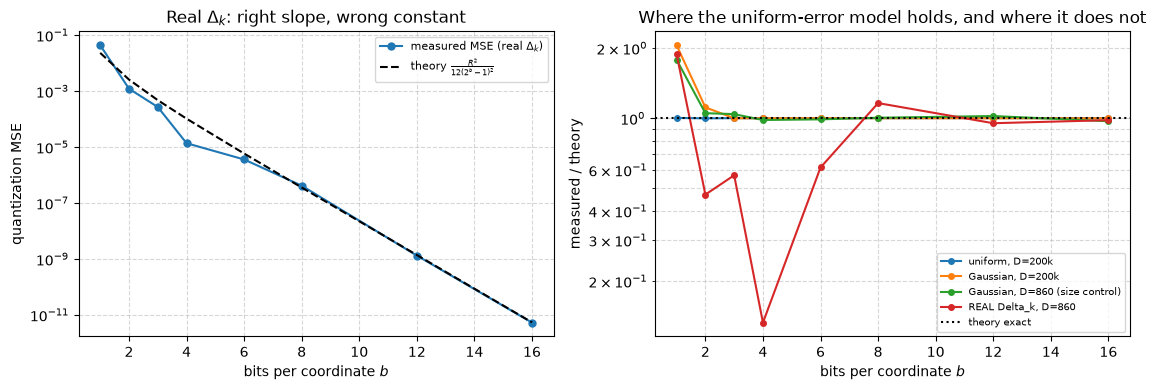

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))

bs = np.array([r[0] for r in q_rows])
mses = np.array([r[1] for r in q_rows])
ths = np.array([r[2] for r in q_rows])

ax[0].semilogy(bs, mses, "o-", ms=5, label=r"measured MSE (real $\Delta_k$)")
ax[0].semilogy(bs, ths, "k--", lw=1.5, label=r"theory $\frac{R^2}{12(2^b-1)^2}$")
ax[0].set_xlabel("bits per coordinate $b$")
ax[0].set_ylabel("quantization MSE")
ax[0].set_title(r"Real $\Delta_k$: right slope, wrong constant")
ax[0].legend(fontsize=8)
ax[0].grid(True, ls="--", alpha=0.5, which="both")

for nm, v in probes:
    ax[1].plot(BITS_GRID, [quant_mse_ratio(v, b)[2] for b in BITS_GRID], "o-", ms=4, label=nm)
ax[1].axhline(1.0, color="k", ls=":", lw=1.5, label="theory exact")
ax[1].set_yscale("log")
ax[1].set_xlabel("bits per coordinate $b$")
ax[1].set_ylabel("measured / theory")
ax[1].set_title("Where the uniform-error model holds, and where it does not")
ax[1].legend(fontsize=7)
ax[1].grid(True, ls="--", alpha=0.5, which="both")

plt.tight_layout()
print("Left : the real MSE falls steeply with b, but sits well BELOW the theory line")
print("       (most of Delta clusters near a level).")
print("Right: uniform data stays at 1.000; Gaussian joins it from b=4; the real Delta never does.")

### Stochastic rounding: unbiased, at a price

**Deterministic rounding is biased.** A value 30% of the way up its cell is *always* rounded
down. Every client gets pulled the same way, so averaging over clients does not remove it.

**Stochastic rounding** rounds up with probability equal to the fractional part. With
$u_i = (v_i - \ell)/s$:

$$q_i = \begin{cases} \lfloor u_i \rfloor + 1 & \text{w.p. } u_i - \lfloor u_i \rfloor \\
\lfloor u_i \rfloor & \text{otherwise}\end{cases}
\qquad \Longrightarrow \qquad \boxed{\mathbb{E}[\hat{v}_i] = v_i}$$

This is the core of **QSGD** (Alistarh et al., 2017). An unbiased compressor is just extra
gradient noise, which SGD tolerates.

**The price:** higher variance, about $s^2/6$ vs $s^2/12$, so **~2× the MSE**. Below we check
both the bias and the variance.


In [15]:
# Verify unbiasedness by Monte Carlo: quantize the SAME vector many times, average.
N_DRAWS = 3000
BITS_T = 2                                     # aggressive, so the effect is unmissable
v_t = D_mat[0][:512]

det = quantize_uniform(v_t, BITS_T)

# bits and n are shapes / trip counts, not data: mark them static, or jnp.arange(n) sees a
# tracer and raises ConcretizationTypeError (Week 4).
@functools.partial(jax.jit, static_argnums=(1, 2))
def sr_mean_and_mse(v, bits, n):
    def body(carry, i):
        acc, sq = carry
        vh = quantize_uniform(v, bits, key=jax.random.fold_in(jax.random.key(0), i),
                              stochastic=True)
        return (acc + vh, sq + jnp.sum((vh - v) ** 2)), 0.0
    (acc, sq), _ = jax.lax.scan(body, (jnp.zeros_like(v), 0.0), jnp.arange(n))
    return acc / n, sq / (n * v.size)

sr_mean, sr_mse = sr_mean_and_mse(v_t, BITS_T, N_DRAWS)
det_mse = float(jnp.mean((det - v_t) ** 2))

bias_det = float(jnp.mean(det - v_t))
bias_sr = float(jnp.mean(sr_mean - v_t))
# Monte-Carlo noise floor on the SR bias estimate: std of the mean over N_DRAWS draws.
lo_t, hi_t = float(jnp.min(v_t)), float(jnp.max(v_t))
s_t = (hi_t - lo_t) / (2 ** BITS_T - 1)
mc_floor = math.sqrt(s_t ** 2 / 6 / N_DRAWS / v_t.size)

print(f"{BITS_T}-bit quantization of a real update slice (D = {v_t.size}), "
      f"{N_DRAWS:,} stochastic draws")
print("-" * 74)
print(f"{'':>28}{'deterministic':>16}{'stochastic':>14}")
print(f"{'mean error (BIAS)':>28}{bias_det:>16.3e}{bias_sr:>14.3e}")
print(f"{'per-coord MSE':>28}{det_mse:>16.3e}{float(sr_mse):>14.3e}")
print(f"{'MSE / (s^2/12)':>28}{det_mse / (s_t ** 2 / 12):>16.3f}{float(sr_mse) / (s_t ** 2 / 12):>14.3f}")
print()
print(f"Monte-Carlo noise floor on the bias estimate : +/- {mc_floor:.2e}")
print(f"  deterministic bias / floor : {abs(bias_det) / mc_floor:>8.1f}   <- REAL, {abs(bias_det) / mc_floor:.0f} sigma from zero")
print(f"  stochastic    bias / floor : {abs(bias_sr) / mc_floor:>8.1f}   <- indistinguishable from zero")
print()
print(f"And the price: stochastic MSE / deterministic MSE = {float(sr_mse) / det_mse:.2f}x")
print(f"  (theory: 2x, i.e. s^2/6 vs s^2/12)")

2-bit quantization of a real update slice (D = 512), 3,000 stochastic draws
--------------------------------------------------------------------------
                               deterministic    stochastic
           mean error (BIAS)      -5.648e-05    -1.666e-06
               per-coord MSE       4.193e-06     7.281e-06
              MSE / (s^2/12)           1.305         2.266

Monte-Carlo noise floor on the bias estimate : +/- 2.05e-06
  deterministic bias / floor :     27.6   <- REAL, 28 sigma from zero
  stochastic    bias / floor :      0.8   <- indistinguishable from zero

And the price: stochastic MSE / deterministic MSE = 1.74x
  (theory: 2x, i.e. s^2/6 vs s^2/12)


In [16]:
# Does the error shrink as we add CLIENTS? Average C(Delta_k) over K clients and see.
print("mean quantization error of the AGGREGATE, as the number of clients grows")
print("(each client quantizes its own Delta_k; the server averages)")
print(f"{'K clients':>10}  {'deterministic':>15}  {'stochastic':>13}")
print("-" * 42)
big = jnp.concatenate([D_mat] * 8, axis=0)          # 40 pseudo-clients from our 5 real ones
for Kc in [1, 2, 5, 10, 20, 40]:
    vs = big[:Kc]
    det_err = float(jnp.mean(jnp.stack([quantize_uniform(v, BITS_T) - v for v in vs])))
    sto_err = float(jnp.mean(jnp.stack([
        quantize_uniform(v, BITS_T, key=jax.random.fold_in(jax.random.key(1), i),
                         stochastic=True) - v for i, v in enumerate(vs)])))
    print(f"{Kc:>10}  {det_err:>15.3e}  {sto_err:>13.3e}")
print()
print("Deterministic: the error does NOT shrink with K. It is bias: every client is")
print("pulled the same way.")
print("Stochastic: shrinks like 1/sqrt(K*D). It is noise, and averaging removes noise.")
print("\nThis is why convergence proofs require unbiasedness.")

mean quantization error of the AGGREGATE, as the number of clients grows
(each client quantizes its own Delta_k; the server averages)
 K clients    deterministic     stochastic
------------------------------------------


         1       -3.217e-02      2.772e-03
         2       -4.200e-02      1.703e-03
         5       -2.089e-02      9.196e-04


        10       -2.089e-02      3.685e-04
        20       -2.089e-02      1.039e-04


        40       -2.089e-02     -1.892e-05

Deterministic: the error does NOT shrink with K. It is bias: every client is
pulled the same way.
Stochastic: shrinks like 1/sqrt(K*D). It is noise, and averaging removes noise.

This is why convergence proofs require unbiasedness.


> **Observe:**
>
> 1. **The $\frac{R^2}{12(2^b-1)^2}$ law holds when its assumption holds.** It is exact on
>    uniform data at every $b$, and on Gaussian data from $b \ge 4$.
> 2. **On the real $\Delta$ it is off by up to ~8×, and the control says why.** It is *not*
>    the small $D$, because Gaussian data with the same $D = 860$ obeys the law. The cause is
>    **heavy tails** (kurtosis 75 vs 3). A few outliers set the range, and 96% of coordinates
>    land in the one cell around zero, **near its centre**. So the error is *smaller* than
>    predicted. A one-line control (same $D$, different distribution) settled the question.
> 3. **At $b=1$ the ratio flips above 1**, for Gaussian data too. The only two levels are the
>    extremes, and mass near zero is far from both. 1-bit needs its own analysis (signSGD),
>    and §9 includes it as an expected failure.
> 4. **Stochastic rounding is unbiased and deterministic is not.** The deterministic bias is
>    ~28 standard errors from zero. More importantly, as clients are added, **the deterministic
>    error stays flat** ($-2.1\times10^{-2}$ from $K=5$ to $K=40$) while the stochastic error
>    shrinks like $1/\sqrt{KD}$. Averaging removes noise, not bias.
>
>    The price we measured is **1.7× the MSE** (theory: 2×). The gap has the same cause as
>    in (2).


---

## 4. Sparsification: fewer coordinates

Keep full precision, but send only $k = dD$ coordinates.

- **Top-$k$** keeps the $k$ largest $|v_i|$. It is **biased**: it is deterministic, so small
  coordinates are zeroed **every round**. That information is not delayed. It is
  **lost**.
- **Random-$k$** keeps each coordinate with probability $d$ and **rescales by $1/d$**. Then
  $\mathbb{E}[\mathcal{C}(v)_i] = d \cdot v_i/d = v_i$, so it is **unbiased**.

Theory prefers random-$k$, but practice uses top-$k$. The usual reason is the **energy
argument**: a few large coordinates hold most of $\lVert\Delta\rVert^2$.

Week 4 found "top 10% keeps ~10%" on `jnp.ones`, where symmetry forces that answer. Here we
measure a real $\Delta$, **with a control**. Even i.i.d. Gaussian noise puts ~44% of its
energy in its top 10%, because squaring favours outliers. The real question: **does $\Delta$
beat a structureless vector with the same variance?**


In [17]:
def topk_mask(v, density):
    k = max(1, int(round(density * v.size)))
    idx = jnp.argsort(jnp.abs(v))[-k:]
    return jnp.zeros_like(v).at[idx].set(v[idx]), idx

def randk(v, density, key, rescale=True):
    # Keep each coordinate independently w.p. d; rescale survivors by 1/d -> UNBIASED.
    keep = (jax.random.uniform(key, v.shape) < density).astype(v.dtype)
    return v * keep / (density if rescale else 1.0)


# The energy curve of a REAL client update, with two controls.
v_e = D_mat[0]
D_e = v_e.size

def energy_curve(v):
    e = np.sort(np.asarray(jnp.abs(v)) ** 2)[::-1]
    return np.cumsum(e) / e.sum()

rg_e = np.random.default_rng(0)
gauss = jnp.asarray(rg_e.normal(scale=float(jnp.std(v_e)), size=D_e).astype(np.float32))
const = jnp.full((D_e,), float(jnp.sqrt(jnp.mean(v_e ** 2))))   # Week 4's all-ones case

# plain keys here; the LaTeX labels live in the plot cell (f-strings cannot hold a backslash)
curves = {"real": energy_curve(v_e), "gauss": energy_curve(gauss), "const": energy_curve(const)}

print(f"fraction of squared norm held by the top d of coordinates, D = {D_e:,}")
print(f"{'d':>8}  {'real Delta':>12}  {'Gaussian ctl':>14}  {'constant':>10}  {'real / Gauss':>13}")
print("-" * 66)
for d in [0.001, 0.01, 0.05, 0.1, 0.2, 0.5]:
    i = max(0, int(d * D_e) - 1)
    r_, g_, c_ = curves["real"][i], curves["gauss"][i], curves["const"][i]
    print(f"{d:>8.3f}  {r_:>11.1%}  {g_:>13.1%}  {c_:>9.1%}  {r_ / g_:>12.2f}x")

i10 = int(0.1 * D_e) - 1
print()
print(f"Week 4 reported 'top 10% keeps ~10%' -- on jnp.ones, where symmetry FORCES it.")
print(f"The real Delta keeps {curves['real'][i10]:.1%} in its top 10%.")
print(f"But structureless Gaussian noise keeps {curves['gauss'][i10]:.1%} -- "
      f"a ratio of only {curves['real'][i10] / curves['gauss'][i10]:.2f}x.")
print("Judge by the last column.")

fraction of squared norm held by the top d of coordinates, D = 860
       d    real Delta    Gaussian ctl    constant   real / Gauss
------------------------------------------------------------------
   0.001        24.1%           1.8%       0.1%         13.18x
   0.010        60.3%           9.6%       0.9%          6.27x
   0.050        98.8%          29.5%       5.0%          3.34x
   0.100        99.3%          44.7%      10.0%          2.22x
   0.200        99.7%          64.3%      20.0%          1.55x
   0.500       100.0%          92.6%      50.0%          1.08x

Week 4 reported 'top 10% keeps ~10%' -- on jnp.ones, where symmetry FORCES it.
The real Delta keeps 99.3% in its top 10%.
But structureless Gaussian noise keeps 44.7% -- a ratio of only 2.22x.
Judge by the last column.


      d   top-k rel err   rand-k rel err    ratio
------------------------------------------------
   0.01           0.598            4.911     8.2x
   0.02           0.422            4.388    10.4x
   0.05           0.110            4.007    36.3x
   0.10           0.082            3.011    36.7x
   0.20           0.054            1.870    34.3x
   0.50           0.017            1.000    58.1x

random-k's 1/d rescaling makes it unbiased but very noisy at small d: the few kept
coordinates are scaled up by 1/d. Unbiased does not mean accurate.


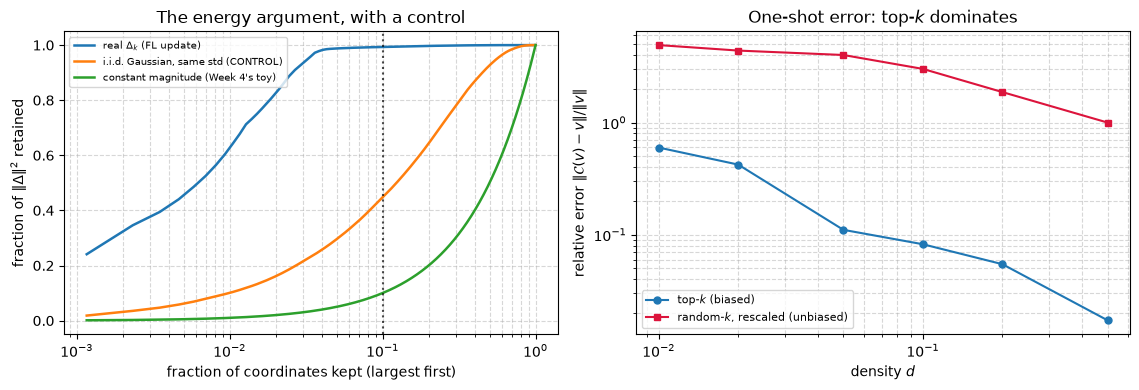

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))

frac = np.arange(1, D_e + 1) / D_e
CURVE_LABELS = {"real": r"real $\Delta_k$ (FL update)",
                "gauss": "i.i.d. Gaussian, same std (CONTROL)",
                "const": "constant magnitude (Week 4's toy)"}
for k_, c in curves.items():
    ax[0].semilogx(frac, c, lw=1.8, label=CURVE_LABELS[k_])
ax[0].axvline(0.1, color="k", ls=":", alpha=0.7)
ax[0].set_xlabel("fraction of coordinates kept (largest first)")
ax[0].set_ylabel("fraction of $\\|\\Delta\\|^2$ retained")
ax[0].set_title("The energy argument, with a control")
ax[0].legend(fontsize=7.5, loc="upper left")
ax[0].grid(True, ls="--", alpha=0.5, which="both")

# top-k vs random-k reconstruction error at matched density
ds = np.array([0.01, 0.02, 0.05, 0.1, 0.2, 0.5])
err_top, err_rand = [], []
for d in ds:
    vt, _ = topk_mask(v_e, float(d))
    err_top.append(float(jnp.linalg.norm(vt - v_e) / jnp.linalg.norm(v_e)))
    es = [float(jnp.linalg.norm(randk(v_e, float(d), jax.random.fold_in(jax.random.key(2), i)) - v_e)
                / jnp.linalg.norm(v_e)) for i in range(5)]
    err_rand.append(float(np.median(es)))

ax[1].loglog(ds, err_top, "o-", ms=5, label="top-$k$ (biased)")
ax[1].loglog(ds, err_rand, "s-", ms=5, color="crimson", label="random-$k$, rescaled (unbiased)")
ax[1].set_xlabel("density $d$")
ax[1].set_ylabel(r"relative error $\|\mathcal{C}(v)-v\| / \|v\|$")
ax[1].set_title("One-shot error: top-$k$ dominates")
ax[1].legend(fontsize=8)
ax[1].grid(True, ls="--", alpha=0.5, which="both")

plt.tight_layout()

print(f"{'d':>7}  {'top-k rel err':>14}  {'rand-k rel err':>15}  {'ratio':>7}")
print("-" * 48)
for d, a_, b_ in zip(ds, err_top, err_rand):
    print(f"{d:>7.2f}  {a_:>14.3f}  {b_:>15.3f}  {b_ / a_:>6.1f}x")
print("\nrandom-k's 1/d rescaling makes it unbiased but very noisy at small d: the few kept")
print("coordinates are scaled up by 1/d. Unbiased does not mean accurate.")

In [19]:
# Verify the bias claim directly: average many draws of each operator and compare to v.
N_B = 400
d_b = 0.1
v_b = v_e[:256]

top_once, _ = topk_mask(v_b, d_b)
rand_acc = jnp.zeros_like(v_b)
for i in range(N_B):
    rand_acc = rand_acc + randk(v_b, d_b, jax.random.fold_in(jax.random.key(3), i))
rand_mean = rand_acc / N_B

bias_top = float(jnp.linalg.norm(top_once - v_b) / jnp.linalg.norm(v_b))
bias_rand = float(jnp.linalg.norm(rand_mean - v_b) / jnp.linalg.norm(v_b))
mc_rand = math.sqrt((1 - d_b) / d_b / N_B)          # rel. std of the mean of rescaled rand-k

print(f"E[C(v)] vs v, averaged over {N_B} draws (d = {d_b}, D = {v_b.size})")
print("-" * 62)
print(f"  top-k    : ||E[C(v)] - v|| / ||v|| = {bias_top:.4f}   <- deterministic, so E[C(v)] = C(v).")
print(f"             {int(round((1 - d_b) * v_b.size))} of {v_b.size} coordinates are zeroed in EVERY draw: bias.")
print(f"  random-k : ||E[C(v)] - v|| / ||v|| = {bias_rand:.4f}   <- shrinks like 1/sqrt(N_draws)")
print(f"             Monte-Carlo floor at this N: ~{mc_rand:.4f}. Consistent with zero bias.")
print()
print("Theory's favourite (random-k) is unbiased; practice's favourite (top-k) is not.")
print("Yet top-k reconstructs 8-58x more accurately per round. Section 5 resolves this,")
print("and Exercise 2 shows the standard theory assumption actually favours top-k.")

E[C(v)] vs v, averaged over 400 draws (d = 0.1, D = 256)
--------------------------------------------------------------
  top-k    : ||E[C(v)] - v|| / ||v|| = 0.6886   <- deterministic, so E[C(v)] = C(v).
             230 of 256 coordinates are zeroed in EVERY draw: bias.
  random-k : ||E[C(v)] - v|| / ||v|| = 0.1483   <- shrinks like 1/sqrt(N_draws)
             Monte-Carlo floor at this N: ~0.1500. Consistent with zero bias.

Theory's favourite (random-k) is unbiased; practice's favourite (top-k) is not.
Yet top-k reconstructs 8-58x more accurately per round. Section 5 resolves this,
and Exercise 2 shows the standard theory assumption actually favours top-k.


> **Observe:**
>
> - **The real $\Delta$ is very concentrated.** The top 10% of coordinates hold **99.3%** of
>   the squared norm, and the top 1% hold 60%. Week 4's toy (~10%) was far off.
> - **The control cuts this down.** Structureless Gaussian noise already holds **44.7%** in its
>   top 10%. Much of the "concentration" just comes from having a spread-out distribution.
> - **A real advantage remains, and it grows as $d$ shrinks:** real/Gaussian is $2.2\times$ at
>   $d=0.1$, $6.3\times$ at $0.01$, and $13.2\times$ at $0.001$. That is the regime
>   sparsification is for. Per round, top-$k$ reconstructs $\Delta$ **8–58×** more accurately
>   than random-$k$.
>
> **This leaves a puzzle.** Top-$k$ is biased but much better per round, while random-$k$ is
> unbiased but much worse. §5 resolves it. Exercise 2 shows that the standard theory
> assumption actually favours top-$k$.


### 🔬 Exercise 2

**The variance of random-$k$.**

1. Derive $\mathbb{E}\lVert\mathcal{C}(v) - v\rVert^2$ for rescaled random-$k$. (Hint: compute
   the variance of $v_i B_i / d$ with $B_i \sim \text{Bernoulli}(d)$.)
2. Check it numerically at $d \in \{0.01, 0.1, 0.5\}$.
3. The standard assumption is $\mathbb{E}\lVert\mathcal{C}(v) - v\rVert^2 \le (1-\delta)\lVert
   v\rVert^2$ with $\delta \in (0, 1]$. What is $\delta$ for random-$k$? For top-$k$? Which is
   better, and does it match the plot?


In [20]:
# --- Reference solution (instructor: blank this out for students) ---

# (1) Per coordinate, C(v)_i = v_i * B_i / d with B_i ~ Bernoulli(d).
#     E[C(v)_i] = v_i          (unbiased)
#     Var(C(v)_i) = v_i^2 / d^2 * Var(B_i) = v_i^2 / d^2 * d(1-d) = v_i^2 * (1-d)/d
#     Summing over i:   E||C(v) - v||^2 = (1-d)/d * ||v||^2
print("(1) Analytic:  E||C(v) - v||^2 = (1-d)/d * ||v||^2   for rescaled random-k")
print("               -> at d = 0.01 that is 99x ||v||^2: unbiased, yet a typical draw")
print("                  is nowhere near v.\n")

# (2)
v_x = v_e
nv2 = float(jnp.sum(v_x ** 2))
print(f"(2) {'d':>6}  {'measured E||C-v||^2':>21}  {'theory (1-d)/d*||v||^2':>24}  {'ratio':>7}")
print("    " + "-" * 62)
for d in [0.01, 0.1, 0.5]:
    # rand-k's error has enormous variance at small d, so the MC estimate needs draws
    errs = [float(jnp.sum((randk(v_x, d, jax.random.fold_in(jax.random.key(9), i)) - v_x) ** 2))
            for i in range(600)]
    meas, th = float(np.mean(errs)), (1 - d) / d * nv2
    mc = float(np.std(errs) / math.sqrt(len(errs))) / th
    print(f"    {d:>6.2f}  {meas:>21.4f}  {th:>24.4f}  {meas / th:>7.3f}  "
          f"(MC +/- {mc:.3f})")

# (3)
print()
print("(3) The assumption E||C(v)-v||^2 <= (1-delta)||v||^2 wants delta as LARGE as possible")
print("    (delta = 1 means C is exact).")
print()
print(f"    {'d':>6}  {'rand-k: 1-delta':>16}  {'delta':>8}  {'top-k: 1-delta':>16}  {'delta':>8}")
print("    " + "-" * 60)
for d in [0.01, 0.1, 0.5]:
    rk = (1 - d) / d                                   # >= 1 for d <= 0.5 -> delta <= 0
    vt, _ = topk_mask(v_x, d)
    tk = float(jnp.sum((vt - v_x) ** 2) / nv2)         # = 1 - (energy kept)
    print(f"    {d:>6.2f}  {rk:>16.3f}  {1 - rk:>8.3f}  {tk:>16.3f}  {1 - tk:>8.3f}")
print()
print("    (At d=0.01 the ratio is below 1 by more than its MC error bar. ||C-v||^2 is itself")
print("     very noisy at small d, which is the point of this exercise: 600 draws cannot")
print("     pin it down. Report that; do not round it away.)")
print()
print("    Read the sign. For rescaled random-k at d <= 0.5, (1-d)/d >= 1, so delta <= 0:")
print("    the bound allows an error larger than ||v|| and says nothing.")
print()
print("    Top-k's 1-delta is (1 - energy kept), measured in Section 4:")
print(f"    at d = 0.1, delta = {1 - float(jnp.sum((topk_mask(v_x, 0.1)[0] - v_x) ** 2) / nv2):.3f}. A truly contractive operator.")
print()
print("    So the standard assumption FAVOURS the biased top-k. That is why the error-feedback")
print("    literature (Stich, Karimireddy) assumes delta-contraction, not unbiasedness: top-k")
print("    can satisfy it. This matches the plot: top-k wins per round.")

(1) Analytic:  E||C(v) - v||^2 = (1-d)/d * ||v||^2   for rescaled random-k
               -> at d = 0.01 that is 99x ||v||^2: unbiased, yet a typical draw
                  is nowhere near v.

(2)      d    measured E||C-v||^2    theory (1-d)/d*||v||^2    ratio
    --------------------------------------------------------------
      0.01                33.3061                   41.4282    0.804  (MC +/- 0.094)


      0.10                 3.5968                    3.7662    0.955  (MC +/- 0.031)
      0.50                 0.4185                    0.4185    1.000  (MC +/- 0.000)

(3) The assumption E||C(v)-v||^2 <= (1-delta)||v||^2 wants delta as LARGE as possible
    (delta = 1 means C is exact).

         d   rand-k: 1-delta     delta    top-k: 1-delta     delta
    ------------------------------------------------------------
      0.01            99.000   -98.000             0.358     0.642
      0.10             9.000    -8.000             0.007     0.993
      0.50             1.000     0.000             0.000     1.000

    (At d=0.01 the ratio is below 1 by more than its MC error bar. ||C-v||^2 is itself
     very noisy at small d, which is the point of this exercise: 600 draws cannot
     pin it down. Report that; do not round it away.)

    Read the sign. For rescaled random-k at d <= 0.5, (1-d)/d >= 1, so delta <= 0:
    the bound allows an error larger than ||v|| and says nothing.



---

## 5. Error feedback: the fix

Top-$k$ throws away $(1-d)D$ coordinates each round. **Instead, remember them.** Each client
keeps a residual $e_k$:

$$
\begin{aligned}
g_k &\leftarrow e_k + \Delta_k \qquad &&\text{(new update + what I still owe)} \\
\tilde{\Delta}_k &\leftarrow \mathcal{C}(g_k) \qquad &&\text{(what I send)} \\
e_k &\leftarrow g_k - \tilde{\Delta}_k \qquad &&\text{(what I still owe)}
\end{aligned}
$$

That is the whole algorithm. A small coordinate builds up in $e_k$ until it makes the top
$k$, and then it is sent. **Nothing is lost, only delayed.**

This is **error feedback** (Seide et al., 2014; Stich et al., 2018; Karimireddy et al., 2019).
With EF, biased contractive compressors recover the convergence rate of uncompressed SGD, up to
constants.

### The catch: clients must keep state

$e_k$ must **persist on the client between rounds**: $O(D)$ memory.

- **Cross-silo** (hospitals, banks, present every round): fine. Use EF.
- **Cross-device** (millions of phones, each sampled maybe *once*): a client that never comes
  back never repays its debt, so the information is lost after all.

This is the same limit SCAFFOLD hit in Week 9: **stateful clients assume clients return.** The
experiment below uses full participation (the friendly cross-silo case). Exercise 3 adds
sampling.

First, the mechanism on its own.


In [21]:
# Mechanism in isolation: compress the SAME vector 60 times and accumulate what arrives.
# Without EF the compressor is deterministic -- it sends the same k coordinates forever,
# and the rest NEVER arrive. With EF the residual grows until every coordinate is paid.
v_m = D_mat[0]
d_m = 0.05
ROUNDS_M = 60

acc_no, acc_ef, e = jnp.zeros_like(v_m), jnp.zeros_like(v_m), jnp.zeros_like(v_m)
cov_no, cov_ef, err_no, err_ef = [], [], [], []
for t in range(ROUNDS_M):
    # no EF: send C(v) every round
    c_no, _ = topk_mask(v_m, d_m)
    acc_no = acc_no + c_no
    # EF: send C(e + v), remember the rest
    g = e + v_m
    c_ef, _ = topk_mask(g, d_m)
    e = g - c_ef
    acc_ef = acc_ef + c_ef
    # what fraction of coordinates has EVER received anything?
    cov_no.append(float(jnp.mean(acc_no != 0)))
    cov_ef.append(float(jnp.mean(acc_ef != 0)))
    # how far is the running mean of what arrived from the truth?
    err_no.append(float(jnp.linalg.norm(acc_no / (t + 1) - v_m) / jnp.linalg.norm(v_m)))
    err_ef.append(float(jnp.linalg.norm(acc_ef / (t + 1) - v_m) / jnp.linalg.norm(v_m)))

print(f"sending the SAME vector {ROUNDS_M} times through top-k at d = {d_m} (D = {v_m.size:,})")
print(f"{'round':>7}  {'coverage no-EF':>15}  {'coverage EF':>12}  {'rel err no-EF':>14}  {'rel err EF':>11}")
print("-" * 68)
for t in [0, 4, 9, 19, 39, 59]:
    print(f"{t + 1:>7}  {cov_no[t]:>14.1%}  {cov_ef[t]:>11.1%}  {err_no[t]:>14.3f}  {err_ef[t]:>11.3f}")
print()
print(f"no EF: coverage is stuck at {cov_no[-1]:.1%} (same top-k every round).")
print(f"       The other {1 - cov_no[-1]:.0%} of the vector is never sent. Not delayed: lost.")
print(f"EF   : coverage reaches {cov_ef[-1]:.1%}, and the running mean converges to the true")
print(f"       vector ({err_ef[-1]:.4f} vs {err_no[-1]:.4f}). Nothing is lost, only delayed.")

sending the SAME vector 60 times through top-k at d = 0.05 (D = 860)
  round   coverage no-EF   coverage EF   rel err no-EF   rel err EF
--------------------------------------------------------------------
      1            5.0%         5.0%           0.110        0.110
      5            5.0%         7.7%           0.110        0.097
     10            5.0%        10.9%           0.110        0.085
     20            5.0%        19.8%           0.110        0.063
     40            5.0%        34.0%           0.110        0.041
     60            5.0%        44.4%           0.110        0.030

no EF: coverage is stuck at 5.0% (same top-k every round).
       The other 95% of the vector is never sent. Not delayed: lost.
EF   : coverage reaches 44.4%, and the running mean converges to the true
       vector (0.0304 vs 0.1104). Nothing is lost, only delayed.


Left: without EF the compressor is a fixed projection: 5% coverage, forever.
Right: no-EF's error plateaus at 0.110 (it converges to the WRONG vector);
       EF's decays to 0.0304. Same bytes per round. Three lines of code.


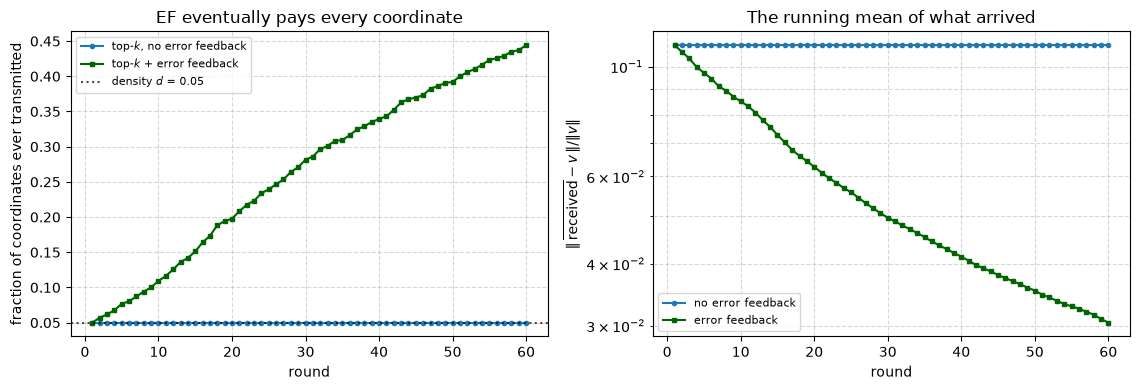

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))

ax[0].plot(np.arange(1, ROUNDS_M + 1), cov_no, "o-", ms=3, label="top-$k$, no error feedback")
ax[0].plot(np.arange(1, ROUNDS_M + 1), cov_ef, "s-", ms=3, color="darkgreen",
           label="top-$k$ + error feedback")
ax[0].axhline(d_m, color="k", ls=":", alpha=0.7, label=f"density $d$ = {d_m}")
ax[0].set_xlabel("round")
ax[0].set_ylabel("fraction of coordinates ever transmitted")
ax[0].set_title("EF eventually pays every coordinate")
ax[0].legend(fontsize=8)
ax[0].grid(True, ls="--", alpha=0.5)

ax[1].semilogy(np.arange(1, ROUNDS_M + 1), err_no, "o-", ms=3, label="no error feedback")
ax[1].semilogy(np.arange(1, ROUNDS_M + 1), err_ef, "s-", ms=3, color="darkgreen",
               label="error feedback")
ax[1].set_xlabel("round")
ax[1].set_ylabel(r"$\|\,\overline{\mathrm{received}} - v\,\| / \|v\|$")
ax[1].set_title("The running mean of what arrived")
ax[1].legend(fontsize=8)
ax[1].grid(True, ls="--", alpha=0.5, which="both")

plt.tight_layout()
print(f"Left: without EF the compressor is a fixed projection: {cov_no[-1]:.0%} coverage, forever.")
print(f"Right: no-EF's error plateaus at {err_no[-1]:.3f} (it converges to the WRONG vector);")
print(f"       EF's decays to {err_ef[-1]:.4f}. Same bytes per round. Three lines of code.")

### Error feedback in the training loop

Now the real claim: **accuracy under FedAvg at aggressive density.** `run_fl` is Week 7's
`run_distributed` with a compressor inserted on the uplink, plus per-client error state. The
server is still `optax.sgd(1.0)` on the pseudo-gradient.


In [23]:
@dataclass
class Scheme:
    # A compression scheme = an operator on the flat Delta + an exact byte model.
    name: str
    fn: object                       # (v, key) -> vhat
    nbytes: object                   # (D, idx or None) -> float
    ef: bool = False
    short: str = ""


def scheme_dense():
    return Scheme("dense float32", lambda v, k: v, lambda D, i: bytes_dense(D), False, "f32")

def scheme_quant(bits, stochastic=False):
    tag = "stoch" if stochastic else "det"
    return Scheme(f"{bits}-bit quant ({tag})",
                  lambda v, k, b=bits, s=stochastic: quantize_uniform(v, b, key=k, stochastic=s),
                  lambda D, i, b=bits: bytes_quantized(D, b),
                  False, f"q{bits}{tag[0]}")

def scheme_topk(density, ef=False, bits=None, index="int32"):
    def fn(v, k, d=density, b=bits):
        vt, idx = topk_mask(v, d)
        if b is not None:
            # quantize only the kept values, then scatter back
            vals = quantize_uniform(v[idx], b, key=k, stochastic=True)
            vt = jnp.zeros_like(v).at[idx].set(vals)
        return vt
    def nb(D, idx, d=density, b=bits, ix=index):
        kk = max(1, int(round(d * D)))
        vb = 4.0 * kk if b is None else (b / 8.0) * kk + 8.0
        if ix == "int32":
            ib = 4.0 * kk
        elif ix == "bitmap":
            ib = D / 8.0
        else:
            ib = bytes_indices(np.asarray(idx), D, ix)
        return vb + ib
    nm = f"top-k d={density}" + (f" + {bits}-bit" if bits else "") + (" + EF" if ef else "")
    return Scheme(nm, fn, nb, ef, f"top{density}{'ef' if ef else ''}")

def scheme_randk(density):
    return Scheme(f"rand-k d={density} (unbiased)",
                  lambda v, k, d=density: randk(v, d, k),
                  lambda D, i, d=density: (4.0 + 4.0) * max(1, int(round(d * D))),
                  False, f"rand{density}")


print("A scheme = (operator, byte model). The byte model is Section 2's exact accounting")
print("and becomes the Pareto plot's x-axis.")
for s in [scheme_dense(), scheme_quant(8), scheme_topk(0.1), scheme_topk(0.1, ef=True),
          scheme_topk(0.1, bits=8, index="bitmap"), scheme_randk(0.1)]:
    print(f"  {s.name:>32}  ->  {s.nbytes(D_PARAMS, idx10):>8.1f} B/round/client  "
          f"({PARAM_BYTES / s.nbytes(D_PARAMS, idx10):>5.1f}x)   EF={s.ef}")

A scheme = (operator, byte model). The byte model is Section 2's exact accounting
and becomes the Pareto plot's x-axis.
                     dense float32  ->    3440.0 B/round/client  (  1.0x)   EF=False
                 8-bit quant (det)  ->     868.0 B/round/client  (  4.0x)   EF=False
                       top-k d=0.1  ->     688.0 B/round/client  (  5.0x)   EF=False
                  top-k d=0.1 + EF  ->     688.0 B/round/client  (  5.0x)   EF=True
               top-k d=0.1 + 8-bit  ->     201.5 B/round/client  ( 17.1x)   EF=False
           rand-k d=0.1 (unbiased)  ->     688.0 B/round/client  (  5.0x)   EF=False


In [24]:
def run_fl(rounds, tau, shards, scheme, *, participation=1.0, weighting="by_size", seed=0):
    # FedAvg in Delta-form (Week 7, Section 6) with a compression operator on the uplink.
    # The FOUR states stay separate; only the parameter Delta is a payload.
    K = len(shards)
    sizes = np.array([len(s) for s in shards], dtype=np.float64)
    server_p, server_b = params0, bn0
    server_opt = optax.sgd(1.0)                        # eta_s = 1 -> EXACTLY FedAvg
    s_state = server_opt.init(params0)
    err = np.zeros((K, D_PARAMS), dtype=np.float32)    # per-client EF state (Section 5)
    rng_sel = np.random.default_rng(seed + 77)
    hist, total_bytes = [], 0.0

    for r in range(rounds):
        # 1-2. broadcast + tau local steps  ->  (K, D) matrix of client updates
        deltas, cb = one_round_deltas(server_p, server_b, shards, tau, r)

        # 3. who participates?
        if participation < 1.0:
            n_sel = max(1, int(round(participation * K)))
            sel_idx = np.sort(rng_sel.choice(K, size=n_sel, replace=False))
        else:
            sel_idx = np.arange(K)

        # 4. THE UPLINK: each selected client compresses its own Delta and pays for it
        sent = np.zeros((K, D_PARAMS), dtype=np.float32)
        round_bytes = 0.0
        for k in sel_idx:
            g = jnp.asarray(err[k]) + deltas[k] if scheme.ef else deltas[k]
            ck = jax.random.fold_in(jax.random.key(seed + 5), r * K + int(k))
            ghat = scheme.fn(g, ck)
            if scheme.ef:
                err[k] = np.asarray(g - ghat)          # remember what we still owe
            sent[k] = np.asarray(ghat)
            idx = np.asarray(jnp.argsort(jnp.abs(g))[-max(1, int(D_PARAMS * 0.1)):])
            round_bytes += scheme.nbytes(D_PARAMS, idx) + 4.0 * BN_VALUES   # bn stats too

        # 5. aggregation weights (Week 7: the weights decide WHICH objective)
        w = np.zeros(K)
        w[sel_idx] = sizes[sel_idx] if weighting == "by_size" else 1.0
        w = w / w.sum()

        # 6. server step: theta <- theta + Delta_bar, i.e. optax.sgd(1.0) on -Delta_bar
        delta_bar = unravel(jnp.asarray(w, jnp.float32) @ jnp.asarray(sent))
        upd, s_state = server_opt.update(jax.tree.map(lambda d: -d, delta_bar), s_state, server_p)
        server_p = eqx.apply_updates(server_p, upd)
        server_b = aggregate(cb, jnp.asarray(w, jnp.float32))

        total_bytes += round_bytes / K                 # MEAN bytes per client
        l, a = evaluate(server_p, server_b, X_te, Y_te)
        hist.append(dict(rnd=r, bytes=total_bytes, loss=float(l), acc=float(a)))
    return hist


ROUNDS = 24
t0 = time.perf_counter()
base_h = run_fl(ROUNDS, TAU, shards_nid, scheme_dense())
print(f"sanity: uncompressed FedAvg, {ROUNDS} rounds of tau={TAU}, Dirichlet alpha={ALPHA}")
print(f"  final test loss {base_h[-1]['loss']:.4f}  acc {base_h[-1]['acc']:.3f}  "
      f"{base_h[-1]['bytes'] / 1e3:.1f} kB/client")
print(f"  ({time.perf_counter() - t0:.1f}s) -- this is the Week 7 codebase with C = identity.")

sanity: uncompressed FedAvg, 24 rounds of tau=8, Dirichlet alpha=0.5
  final test loss 0.8389  acc 0.845  85.8 kB/client
  (3.4s) -- this is the Week 7 codebase with C = identity.


In [25]:
# THE experiment: top-k at aggressive density, with and without error feedback.
ef_configs = [
    ("dense float32 (no compression)", scheme_dense()),
    ("top-k d=0.10, no EF",            scheme_topk(0.10)),
    ("top-k d=0.10, + EF",             scheme_topk(0.10, ef=True)),
    ("top-k d=0.01, no EF",            scheme_topk(0.01)),
    ("top-k d=0.01, + EF",             scheme_topk(0.01, ef=True)),
]

print(f"FedAvg, {ROUNDS} rounds, tau={TAU}, Dirichlet alpha={ALPHA}, K={K_CLIENTS}, full participation")
print(f"{'configuration':>32}  {'test loss':>10}  {'test acc':>9}  {'kB/client':>10}  {'vs dense':>9}")
print("-" * 78)
ef_rows = []
t0 = time.perf_counter()
for label, sch in ef_configs:
    h = run_fl(ROUNDS, TAU, shards_nid, sch)
    ef_rows.append((label, h, sch))
    b0 = ef_rows[0][1][-1]["bytes"]
    print(f"{label:>32}  {h[-1]['loss']:>10.4f}  {h[-1]['acc']:>9.3f}  "
          f"{h[-1]['bytes'] / 1e3:>10.2f}  {b0 / h[-1]['bytes']:>8.1f}x")
print(f"\n({time.perf_counter() - t0:.1f}s on {jax.devices()[0].device_kind})")

acc = {l: h[-1]["acc"] for l, h, _ in ef_rows}
print(f"\nAt d = 0.01 (1% of coordinates), the SAME bytes:")
print(f"  no EF : acc {acc['top-k d=0.01, no EF']:.3f}")
print(f"  + EF  : acc {acc['top-k d=0.01, + EF']:.3f}   "
      f"<- recovers {100 * (acc['top-k d=0.01, + EF'] - acc['top-k d=0.01, no EF']) / max(1e-9, acc['dense float32 (no compression)'] - acc['top-k d=0.01, no EF']):.0f}% of the gap to dense")
print(f"  dense : acc {acc['dense float32 (no compression)']:.3f}")

FedAvg, 24 rounds, tau=8, Dirichlet alpha=0.5, K=5, full participation
                   configuration   test loss   test acc   kB/client   vs dense
------------------------------------------------------------------------------


  dense float32 (no compression)      0.8389      0.845       85.82       1.0x


             top-k d=0.10, no EF      1.1123      0.619       19.78       4.3x


              top-k d=0.10, + EF      0.9147      0.840       19.78       4.3x


             top-k d=0.01, no EF      1.3752      0.301        4.99      17.2x


              top-k d=0.01, + EF      1.3560      0.381        4.99      17.2x

(11.5s on cpu)

At d = 0.01 (1% of coordinates), the SAME bytes:
  no EF : acc 0.301
  + EF  : acc 0.381   <- recovers 15% of the gap to dense
  dense : acc 0.845


identical byte budget at d=0.01 (4.99 kB/client, 17x less than dense):
  no EF : final acc 0.301, loss 1.3752
  + EF  : final acc 0.381, loss 1.3560
  dense : final acc 0.845, loss 0.8389

Right panel: at any fixed byte budget, the EF curves sit ABOVE the no-EF curves.
Three lines of client code, zero extra bytes.


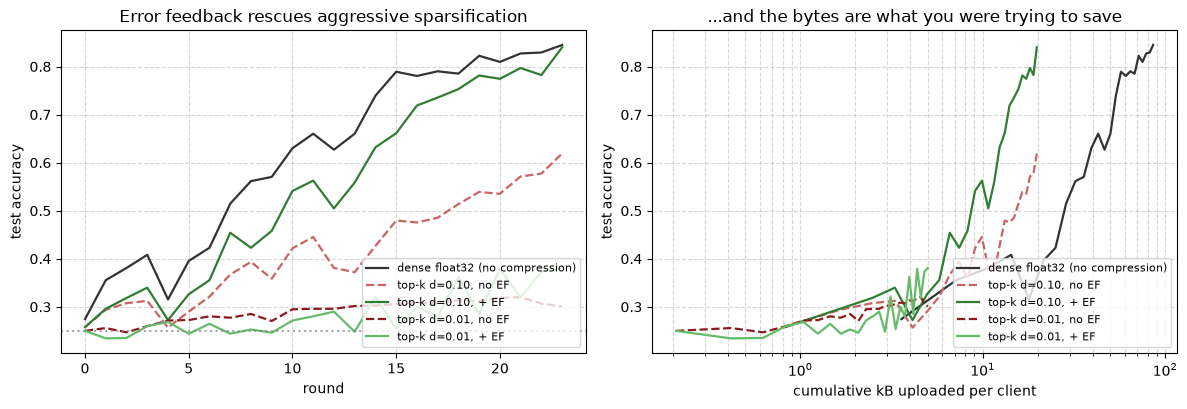

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
cols_ef = ["#333333", "#c86464", "#2e7d32", "#8b1a1a", "#66bb6a"]
styles = ["-", "--", "-", "--", "-"]

for (label, h, _), c, st in zip(ef_rows, cols_ef, styles):
    ax[0].plot([d["rnd"] for d in h], [d["acc"] for d in h], st, color=c, lw=1.6, label=label)
ax[0].set_xlabel("round")
ax[0].set_ylabel("test accuracy")
ax[0].set_title("Error feedback rescues aggressive sparsification")
ax[0].legend(fontsize=8, loc="lower right")
ax[0].grid(True, ls="--", alpha=0.5)
ax[0].axhline(1 / N_CLASSES, color="gray", ls=":", alpha=0.7)

for (label, h, _), c, st in zip(ef_rows, cols_ef, styles):
    ax[1].semilogx([d["bytes"] / 1e3 for d in h], [d["acc"] for d in h], st, color=c, lw=1.6,
                   label=label)
ax[1].set_xlabel("cumulative kB uploaded per client")
ax[1].set_ylabel("test accuracy")
ax[1].set_title("...and the bytes are what you were trying to save")
ax[1].legend(fontsize=8, loc="lower right")
ax[1].grid(True, ls="--", alpha=0.5, which="both")

plt.tight_layout()

d01_no = [h for l, h, _ in ef_rows if l == "top-k d=0.01, no EF"][0]
d01_ef = [h for l, h, _ in ef_rows if l == "top-k d=0.01, + EF"][0]
dense = ef_rows[0][1]
print(f"identical byte budget at d=0.01 ({d01_no[-1]['bytes'] / 1e3:.2f} kB/client, "
      f"{dense[-1]['bytes'] / d01_no[-1]['bytes']:.0f}x less than dense):")
print(f"  no EF : final acc {d01_no[-1]['acc']:.3f}, loss {d01_no[-1]['loss']:.4f}")
print(f"  + EF  : final acc {d01_ef[-1]['acc']:.3f}, loss {d01_ef[-1]['loss']:.4f}")
print(f"  dense : final acc {dense[-1]['acc']:.3f}, loss {dense[-1]['loss']:.4f}")
print(f"\nRight panel: at any fixed byte budget, the EF curves sit ABOVE the no-EF curves.")
print("Three lines of client code, zero extra bytes.")

> **Observe:**
>
> - **At $d=0.10$, EF is decisive.** Plain top-$k$ falls to **0.619** (dense: **0.845**). EF
>   brings it back to **0.840** at **identical bytes**. In §4, top-$k$ at $d=0.1$ reconstructed
>   one $\Delta$ within 8%, yet training still broke. A small bias, repeated in the same
>   direction for 24 rounds, adds up. The isolated demo shows why: without EF, coverage is stuck
>   at 5% and the error plateaus at 0.110. With EF, coverage reaches 44% and the error falls to
>   0.030.
> - **At $d=0.01$, EF helps only a little:** 0.301 → **0.381**, about 15% of the gap. Each
>   client sends **9 numbers per round**, and the debt grows faster than 24 rounds can repay.
>   **EF turns a permanent bias into a delay. If the delay exceeds your round budget, that does
>   not help.**
> - So in this run EF helped **more at the moderate density than at the extreme one.** EF needs
>   enough bandwidth to repay its debt.
>
> **Caveats.** (1) This is the friendly case: full participation and 5 clients. Exercise 3
> removes that. (2) Single seed and 24 rounds. The $d=0.1$ effect (+0.22) is far too large to
> be noise, but the $d=0.01$ effect (+0.08) needs more seeds. (3) $e_k$ is as large as the
> model, and it is *state*.


---

## 6. Client sampling: the other factor

Sampling a fraction $C$ of clients per round cuts the total uplink by a factor of $1/C$. It
**multiplies** with compression. Week 7 found partial participation "nearly free — **on IID**".
Now the data are non-IID, and two separate problems appear:

**1. Variance.** A sample's $\bar\Delta$ is a noisy estimate of the full one. On non-IID data,
clients point in different directions, so the noise is much larger.

**2. Bias in FedAvg's own weights.** Sample $S_r$ uniformly and aggregate as McMahan et al.
specify:

$$\bar\Delta_{S} = \sum_{k \in S_r} \frac{n_k}{\sum_{j \in S_r} n_j}\,\Delta_k$$

The denominator is **random**, so this is a **ratio estimator**, and those are biased
($\mathbb{E}[X/Y] \ne \mathbb{E}[X]/\mathbb{E}[Y]$). **The fix:** sample clients with
probability $\propto n_k$, then average **uniformly**. That estimator is exactly unbiased.

We can check this **without training**: fix the $\Delta_k$, vary only the sampling.


In [27]:
# Is sampled FedAvg's aggregate an unbiased estimate of the full-participation aggregate?
# Fix the Delta_k, vary ONLY the sampling. No training, no optimizer -- just the estimator.
sizes_nid = np.array([len(s) for s in shards_nid], dtype=np.float64)
p_full = sizes_nid / sizes_nid.sum()
target = np.asarray(jnp.asarray(p_full, jnp.float32) @ D_mat)      # the estimand

N_MC = 20000
rg_s = np.random.default_rng(0)
m = 2                                                              # sample 2 of 5 clients

est_ratio = np.zeros(D_PARAMS, dtype=np.float64)      # FedAvg as written: n_k / sum_{S} n_j
est_unif = np.zeros(D_PARAMS, dtype=np.float64)       # uniform weights over a uniform sample
est_pps = np.zeros(D_PARAMS, dtype=np.float64)        # prob. proportional to size + uniform avg
Dnp = np.asarray(D_mat, dtype=np.float64)

for _ in range(N_MC):
    S = rg_s.choice(K_CLIENTS, size=m, replace=False)
    w = sizes_nid[S] / sizes_nid[S].sum()
    est_ratio += w @ Dnp[S]
    est_unif += Dnp[S].mean(axis=0)
    T = rg_s.choice(K_CLIENTS, size=m, replace=True, p=p_full)     # PPS, with replacement
    est_pps += Dnp[T].mean(axis=0)

est_ratio /= N_MC; est_unif /= N_MC; est_pps /= N_MC
nt = np.linalg.norm(target)
mc_floor_s = np.linalg.norm(Dnp.std(axis=0)) / math.sqrt(N_MC) / nt

print(f"Estimand: full-participation FedAvg aggregate, sum_k (n_k/n) Delta_k")
print(f"Sampling {m} of {K_CLIENTS} clients, {N_MC:,} Monte-Carlo draws. n_k = {sizes_nid.astype(int)}")
print("-" * 78)
print(f"{'estimator':>44}  {'rel. bias':>11}  {'vs MC floor':>12}")
print("-" * 78)
for nm, e in [("FedAvg as written: n_k / sum_{j in S} n_j", est_ratio),
              ("uniform sample + uniform weights", est_unif),
              ("size-proportional sample + uniform weights", est_pps)]:
    rb = np.linalg.norm(e - target) / nt
    print(f"{nm:>44}  {rb:>11.5f}  {rb / mc_floor_s:>11.1f}x")
print(f"{'(Monte-Carlo noise floor)':>44}  {mc_floor_s:>11.5f}  {1.0:>11.1f}x")
print()
print("'vs MC floor' near 1 means indistinguishable from unbiased.")
print("FedAvg's ratio estimator is BIASED: its denominator is random.")
print("Uniform weights are biased differently: they estimate the WRONG target,")
print("(1/K) sum_k Delta_k, which differs from sum_k (n_k/n) Delta_k when the n_k differ.")
print("Only size-proportional sampling + uniform averaging is unbiased.")

Estimand: full-participation FedAvg aggregate, sum_k (n_k/n) Delta_k
Sampling 2 of 5 clients, 20,000 Monte-Carlo draws. n_k = [ 137  868 1487 1558   46]
------------------------------------------------------------------------------
                                   estimator    rel. bias   vs MC floor
------------------------------------------------------------------------------
   FedAvg as written: n_k / sum_{j in S} n_j      0.46400         24.0x
            uniform sample + uniform weights      1.02094         52.9x
  size-proportional sample + uniform weights      0.01885          1.0x
                   (Monte-Carlo noise floor)      0.01931          1.0x

'vs MC floor' near 1 means indistinguishable from unbiased.
FedAvg's ratio estimator is BIASED: its denominator is random.
Uniform weights are biased differently: they estimate the WRONG target,
(1/K) sum_k Delta_k, which differs from sum_k (n_k/n) Delta_k when the n_k differ.
Only size-proportional sampling + uniform averagin

In [28]:
# Now the optimizer-level question: what does sampling cost in ACCURACY, IID vs non-IID?
Cs = [0.2, 0.4, 0.6, 1.0]

print(f"client sampling sweep, {ROUNDS} rounds, tau={TAU}, dense float32 (no compression)")
print(f"{'C':>5}  {'clients/rnd':>12}  {'IID acc':>9}  {'IID kB':>8}  {'nIID acc':>10}  {'nIID kB':>9}")
print("-" * 62)
samp_rows = []
t0 = time.perf_counter()
for C in Cs:
    hi = run_fl(ROUNDS, TAU, shards_iid, scheme_dense(), participation=C, seed=1)
    hn = run_fl(ROUNDS, TAU, shards_nid, scheme_dense(), participation=C, seed=1)
    samp_rows.append((C, hi, hn))
    print(f"{C:>5.1f}  {max(1, int(round(C * K_CLIENTS))):>12}  {hi[-1]['acc']:>9.3f}  "
          f"{hi[-1]['bytes'] / 1e3:>8.2f}  {hn[-1]['acc']:>10.3f}  {hn[-1]['bytes'] / 1e3:>9.2f}")
print(f"\n({time.perf_counter() - t0:.1f}s)")

drop_iid = samp_rows[-1][1][-1]["acc"] - samp_rows[0][1][-1]["acc"]
drop_nid = samp_rows[-1][2][-1]["acc"] - samp_rows[0][2][-1]["acc"]
print(f"accuracy change from C=1.0 to C=0.2:")
print(f"  IID     : {-drop_iid:+.3f}   (for a {samp_rows[-1][1][-1]['bytes'] / samp_rows[0][1][-1]['bytes']:.1f}x byte saving)")
print(f"  non-IID : {-drop_nid:+.3f}   (for a {samp_rows[-1][2][-1]['bytes'] / samp_rows[0][2][-1]['bytes']:.1f}x byte saving)")

client sampling sweep, 24 rounds, tau=8, dense float32 (no compression)
    C   clients/rnd    IID acc    IID kB    nIID acc    nIID kB
--------------------------------------------------------------


  0.2             1      0.771     17.16       0.491      17.16


  0.4             2      0.853     34.33       0.734      34.33


  0.6             3      0.833     51.49       0.562      51.49


  1.0             5      0.844     85.82       0.845      85.82

(17.7s)
accuracy change from C=1.0 to C=0.2:
  IID     : -0.073   (for a 5.0x byte saving)
  non-IID : -0.354   (for a 5.0x byte saving)


Left : accuracy cost of sampling.  Right: sampling error of one round's aggregate,
measured on real Delta_k with no training.

Non-IID updates point in DIFFERENT directions, so a subset summarizes the whole
much worse than on IID data.


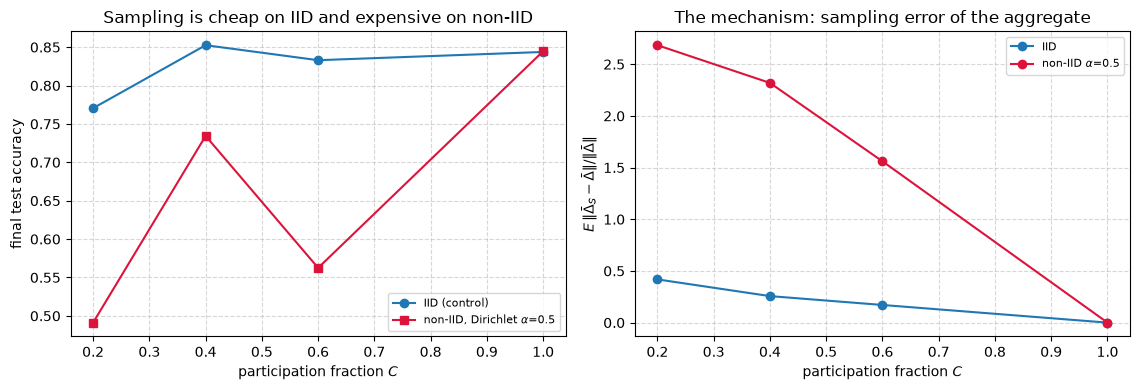

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))

ax[0].plot([r[0] for r in samp_rows], [r[1][-1]["acc"] for r in samp_rows], "o-",
           label=f"IID (control)")
ax[0].plot([r[0] for r in samp_rows], [r[2][-1]["acc"] for r in samp_rows], "s-",
           color="crimson", label=f"non-IID, Dirichlet $\\alpha$={ALPHA}")
ax[0].set_xlabel("participation fraction $C$")
ax[0].set_ylabel("final test accuracy")
ax[0].set_title("Sampling is cheap on IID and expensive on non-IID")
ax[0].legend(fontsize=8)
ax[0].grid(True, ls="--", alpha=0.5)

# round-to-round variance of the aggregate is the mechanism
for lab, sh, c in [("IID", shards_iid, "C0"), (f"non-IID $\\alpha$={ALPHA}", shards_nid, "crimson")]:
    dm, _ = one_round_deltas(params0, bn0, sh, TAU, 0)
    dmn = np.asarray(dm, dtype=np.float64)
    szs = np.array([len(s) for s in sh], dtype=np.float64)
    tgt = (szs / szs.sum()) @ dmn
    rgv = np.random.default_rng(0)
    xs_, ys_ = [], []
    for C in Cs:
        mm = max(1, int(round(C * K_CLIENTS)))
        errs = []
        for _ in range(400):
            S = rgv.choice(K_CLIENTS, size=mm, replace=False)
            w = szs[S] / szs[S].sum()
            errs.append(np.linalg.norm(w @ dmn[S] - tgt) / np.linalg.norm(tgt))
        xs_.append(C); ys_.append(np.mean(errs))
    ax[1].plot(xs_, ys_, "o-", color=c, label=lab)
ax[1].set_xlabel("participation fraction $C$")
ax[1].set_ylabel(r"$E\,\|\bar\Delta_S - \bar\Delta\| / \|\bar\Delta\|$")
ax[1].set_title("The mechanism: sampling error of the aggregate")
ax[1].legend(fontsize=8)
ax[1].grid(True, ls="--", alpha=0.5)

plt.tight_layout()
print("Left : accuracy cost of sampling.  Right: sampling error of one round's aggregate,")
print("measured on real Delta_k with no training.")
print("\nNon-IID updates point in DIFFERENT directions, so a subset summarizes the whole")
print("much worse than on IID data.")

> **Observe:**
>
> - **FedAvg's sampled estimator is biased.** With fixed $\Delta_k$ and 20,000 draws, the
>   $n_k/\sum_{j\in S} n_j$ estimator sits **24×** the Monte-Carlo floor away from the
>   target. Size-proportional sampling + uniform averaging sits at **1.0×**, which is
>   unbiased. This is pure arithmetic with no optimizer involved.
> - **Non-IID makes sampling noisy.** Right panel: a subset of non-IID clients summarizes the
>   population much worse than a subset of IID clients. Going from $C=1.0$ to $C=0.2$ costs
>   **0.07** accuracy on IID but **0.35** on non-IID.
>
> **How much the accuracy panel supports:** with $K=5$, $C=0.2$ is *one* client per round, and
> it is a single seed. The non-IID curve is even non-monotone (0.734 at $C=0.4$, 0.562 at
> $0.6$). The estimator experiment is the solid evidence, and the training panel only agrees
> with it. At the real lab's 100 clients and $C = 0.01$–$0.1$, this effect dominates.


### 🔬 Exercise 3

**Error feedback meets client sampling.** §5 ran EF with every client present every round.
Real cross-device FL samples clients.

Run top-$k$ at $d=0.01$ with and without EF, at $C \in \{0.4, 1.0\}$.

1. Does EF still help at $C = 0.4$? Compare with $C = 1.0$.
2. A waiting client's $e_k$ **goes stale**: it was computed against an old $\theta$. Relate
   this to Week 7's **staleness**.
3. If a client is sampled **once, ever**, what is EF worth? Which of §3–§5's schemes should a
   phone use?


In [30]:
# --- Reference solution (instructor: blank this out for students) ---

print(f"top-k d=0.01, {ROUNDS} rounds, non-IID -- does EF survive client sampling?")
print(f"{'C':>6}  {'no EF acc':>10}  {'+ EF acc':>9}  {'EF benefit':>11}  {'kB/client':>10}")
print("-" * 54)
ex3 = {}
for C in [0.4, 1.0]:
    h_no = run_fl(ROUNDS, TAU, shards_nid, scheme_topk(0.01), participation=C, seed=2)
    h_ef = run_fl(ROUNDS, TAU, shards_nid, scheme_topk(0.01, ef=True), participation=C, seed=2)
    ex3[C] = (h_no, h_ef)
    print(f"{C:>6.1f}  {h_no[-1]['acc']:>10.3f}  {h_ef[-1]['acc']:>9.3f}  "
          f"{h_ef[-1]['acc'] - h_no[-1]['acc']:>+11.3f}  {h_ef[-1]['bytes'] / 1e3:>10.2f}")

b_full = ex3[1.0][1][-1]["acc"] - ex3[1.0][0][-1]["acc"]
b_part = ex3[0.4][1][-1]["acc"] - ex3[0.4][0][-1]["acc"]
print()
print(f"(1) EF benefit at C=1.0 : {b_full:+.3f}")
print(f"    EF benefit at C=0.4 : {b_part:+.3f}")
print()
print("    At C=0.4 EF's benefit is GONE (slightly negative on this seed). Each client is")
print("    seen ~C as often, so a debt takes ~1/C times as many rounds to repay, and by then")
print("    the model has moved. A residual repaid against an old theta adds noise, not a fix.")
print("    (One seed and a small gap: do not over-read the SIGN. The safe claim is that the")
print("    large C=1.0 benefit does not survive sampling.)")
print()
print("(2) This is Week 7's staleness. e_k was computed against theta^(r); the client")
print("    returns at round r + s and adds it to a Delta computed against theta^(r+s).")
print("    The residual belongs to a point that no longer exists: the async-SGD problem,")
print("    and it gets worse with s in the same way.")
print()
print("(3) Sampled once => e_k is never sent, so the 'delayed' information is lost after all.")
print("    EF needs a second visit. In true cross-device FL it is worth ~ZERO.")
print("    So a phone should use an UNBIASED, STATELESS compressor (QSGD or rescaled")
print("    random-k). Its error averages out ACROSS CLIENTS (thousands per round), not")
print("    ACROSS ROUNDS (which a one-time client does not have).")
print()
print("    Design rule: cross-silo -> top-k + EF. Cross-device -> stochastic quantization.")
print("    Same as SCAFFOLD vs FedProx in Week 9: statefulness decides.")

top-k d=0.01, 24 rounds, non-IID -- does EF survive client sampling?
     C   no EF acc   + EF acc   EF benefit   kB/client
------------------------------------------------------


   0.4       0.274      0.252       -0.022        2.00


   1.0       0.301      0.381       +0.080        4.99

(1) EF benefit at C=1.0 : +0.080
    EF benefit at C=0.4 : -0.022

    At C=0.4 EF's benefit is GONE (slightly negative on this seed). Each client is
    seen ~C as often, so a debt takes ~1/C times as many rounds to repay, and by then
    the model has moved. A residual repaid against an old theta adds noise, not a fix.
    (One seed and a small gap: do not over-read the SIGN. The safe claim is that the
    large C=1.0 benefit does not survive sampling.)

(2) This is Week 7's staleness. e_k was computed against theta^(r); the client
    returns at round r + s and adds it to a Delta computed against theta^(r+s).
    The residual belongs to a point that no longer exists: the async-SGD problem,
    and it gets worse with s in the same way.

(3) Sampled once => e_k is never sent, so the 'delayed' information is lost after all.
    EF needs a second visit. In true cross-device FL it is worth ~ZERO.
    So a phone should use an UNBIASE

---

## 7. Stragglers: the round is as slow as its slowest client

A **synchronous** round ends when the *last* client reports:

$$T_{\text{round}} = \max_{k \in S_r} T_k$$

The max of more samples is larger, so **the round gets slower as you add clients**, even with
identical per-client work. Phones vary a lot (chip, heat, battery, radio), so this is worse
than in a datacenter.

Three responses:

1. **Wait** (vanilla FedAvg). Correct, but you pay the max.
2. **Deadline + drop** (common in production). This is fast but **biased**. Slow devices are
   not random. They are older phones on worse networks. Dropping them is a *fairness* choice
   (Week 14).
3. **Buffered async** (**FedBuff**, Nguyen et al., 2022). The server updates after any $b$
   arrivals. Throughput rises, and the price is **staleness**, the cost Week 7 measured.

**This section is a simulation.** Client times are LogNormal, not measured. Only the *shape*
of the argument transfers.


In [31]:
# Client compute+upload time ~ LogNormal, the standard model: chip speed, heat, radio
# and battery policy multiply.
SIGMA = 0.8
rg_t = np.random.default_rng(0)

def client_times(n, sigma=SIGMA, size=None):
    return rg_t.lognormal(mean=0.0, sigma=sigma, size=(size, n) if size else n)

Ks = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000])
N_SIM = 2000

print(f"round time = max over K clients, T_k ~ LogNormal(0, sigma={SIGMA}), {N_SIM:,} sims")
print(f"{'K':>6}  {'E[mean T]':>10}  {'E[max T]':>10}  {'max/mean':>9}  {'p50 max':>9}  {'p95 max':>9}")
print("-" * 62)
sim = {}
for K_ in Ks:
    T = client_times(int(K_), size=N_SIM)
    mx, mn = T.max(axis=1), T.mean(axis=1)
    sim[int(K_)] = (mx, mn)
    print(f"{K_:>6}  {mn.mean():>10.3f}  {mx.mean():>10.3f}  {mx.mean() / mn.mean():>9.2f}x  "
          f"{np.percentile(mx, 50):>9.3f}  {np.percentile(mx, 95):>9.3f}")

print(f"\nEvery client does the SAME work at every K. The round still gets "
      f"{sim[1000][0].mean() / sim[1][0].mean():.1f}x slower")
print(f"from K=1 to K=1000, only because the worst case gets worse.")
print("Synchronous FL penalizes more participants, and cross-device FL has many.")

round time = max over K clients, T_k ~ LogNormal(0, sigma=0.8), 2,000 sims
     K   E[mean T]    E[max T]   max/mean    p50 max    p95 max
--------------------------------------------------------------
     1       1.339       1.339       1.00x      0.974      3.594
     2       1.389       2.008       1.45x      1.580      4.899
     5       1.378       2.905       2.11x      2.429      6.268
    10       1.383       3.906       2.82x      3.317      8.113
    20       1.374       4.953       3.60x      4.314      9.476
    50       1.380       6.549       4.75x      5.839     11.988
   100       1.378       7.838       5.69x      7.074     13.686
   200       1.379       9.501       6.89x      8.716     15.914
   500       1.377      11.884       8.63x     10.895     19.215
  1000       1.376      13.920      10.12x     12.913     22.250

Every client does the SAME work at every K. The round still gets 10.4x slower
from K=1 to K=1000, only because the worst case gets worse.
Synchrono

In [32]:
# Deadline + drop: the production answer, and its bias.
K_D = 100
T_d = client_times(K_D, size=N_SIM)
deadlines = np.percentile(T_d.ravel(), [30, 50, 70, 80, 90, 95, 99, 100])

print(f"deadline sweep, K = {K_D} sampled clients per round")
print(f"{'deadline':>10}  {'E[clients kept]':>16}  {'round time':>11}  {'clients/sec':>12}")
print("-" * 54)
dl_rows = []
for dl in deadlines:
    kept = (T_d <= dl).sum(axis=1).mean()
    # round time is the deadline, unless everyone finished early
    rt = np.minimum(T_d.max(axis=1), dl).mean()
    dl_rows.append((dl, kept, rt, kept / rt))
    print(f"{dl:>10.3f}  {kept:>16.1f}  {rt:>11.3f}  {kept / rt:>12.1f}")

best_dl = max(dl_rows, key=lambda r: r[3])
print(f"\nthroughput-optimal deadline: {best_dl[0]:.3f} -> keeps {best_dl[1]:.0f}/{K_D} clients, "
      f"{best_dl[3]:.1f} clients/sec")
print(f"waiting for everyone      : {dl_rows[-1][0]:.3f} -> keeps {dl_rows[-1][1]:.0f}/{K_D} clients, "
      f"{dl_rows[-1][3]:.1f} clients/sec")
print(f"\nThe tight deadline is {best_dl[3] / dl_rows[-1][3]:.1f}x better on throughput and drops "
      f"{K_D - best_dl[1]:.0f} clients EVERY ROUND.")
print("They are not random clients. They are the slow ones: older devices, worse radios,")
print("and (in deployed systems) often poorer users. The systems knob IS a fairness knob.")
print("Week 14 turns this into a measurable requirement.")

deadline sweep, K = 100 sampled clients per round
  deadline   E[clients kept]   round time   clients/sec
------------------------------------------------------
     0.658              30.0        0.658          45.6
     1.002              50.0        1.002          49.9
     1.526              70.0        1.526          45.9
     1.972              80.0        1.972          40.6
     2.800              90.0        2.800          32.1
     3.748              95.0        3.747          25.4
     6.522              99.0        6.095          16.2
    27.907             100.0        7.917          12.6

throughput-optimal deadline: 1.002 -> keeps 50/100 clients, 49.9 clients/sec
waiting for everyone      : 27.907 -> keeps 100/100 clients, 12.6 clients/sec

The tight deadline is 4.0x better on throughput and drops 50 clients EVERY ROUND.
They are not random clients. They are the slow ones: older devices, worse radios,
and (in deployed systems) often poorer users. The systems knob IS a fa

In [33]:
# FedBuff-style: aggregate after the first b arrivals. Throughput vs staleness.
def simulate_fedbuff(n_updates, K_conc, buffer, sigma=SIGMA, seed=0):
    # K_conc clients in flight; whenever one finishes, it reports and is immediately
    # replaced. The server steps once every `buffer` arrivals. Staleness = how many server
    # steps happened between a client's start and its arrival.
    r = np.random.default_rng(seed)
    finish = r.lognormal(0.0, sigma, K_conc)                 # absolute finish times
    start_v = np.zeros(K_conc)                               # server version at start
    version, arrivals, stale, t_now = 0, 0, [], 0.0
    pending = 0
    while arrivals < n_updates:
        j = int(np.argmin(finish))
        t_now = finish[j]
        stale.append(version - start_v[j])
        arrivals += 1
        pending += 1
        if pending >= buffer:
            version += 1
            pending = 0
        finish[j] = t_now + r.lognormal(0.0, sigma)          # relaunch this client
        start_v[j] = version
    return t_now, np.array(stale)


K_CONC, N_UPD = 50, 3000
print(f"FedBuff simulation: {K_CONC} clients in flight, {N_UPD:,} updates consumed")
print(f"{'buffer b':>9}  {'server steps':>13}  {'wall time':>10}  {'steps/sec':>10}  "
      f"{'mean staleness':>15}  {'p95':>6}")
print("-" * 72)
fb_rows = []
for b in [1, 2, 5, 10, 25, 50]:
    t_end, st = simulate_fedbuff(N_UPD, K_CONC, b)
    steps = N_UPD // b
    fb_rows.append((b, steps, t_end, steps / t_end, st.mean(), np.percentile(st, 95)))
    print(f"{b:>9}  {steps:>13}  {t_end:>10.2f}  {steps / t_end:>10.2f}  "
          f"{st.mean():>15.2f}  {np.percentile(st, 95):>6.0f}")

# synchronous baseline: same client population, rounds of K_CONC, wait for the max
T_sync = client_times(K_CONC, size=N_UPD // K_CONC)
t_sync = T_sync.max(axis=1).sum()
print(f"\n{'synchronous':>9}  {N_UPD // K_CONC:>13}  {t_sync:>10.2f}  "
      f"{(N_UPD // K_CONC) / t_sync:>10.2f}  {0.0:>15.2f}  {0:>6}")
print(f"\nFedBuff(b={K_CONC}) vs synchronous at the same buffer size: "
      f"{fb_rows[-1][3] / ((N_UPD // K_CONC) / t_sync):.2f}x the server steps per unit time,")
print(f"bought with {fb_rows[-1][4]:.1f} mean staleness. Sync waits for the max; FedBuff never waits.")

FedBuff simulation: 50 clients in flight, 3,000 updates consumed
 buffer b   server steps   wall time   steps/sec   mean staleness     p95
------------------------------------------------------------------------
        1           3000       79.96       37.52            48.35     132
        2           1500       79.96       18.76            24.17      66
        5            600       79.96        7.50             9.66      27
       10            300       79.96        3.75             4.83      13
       25            120       79.96        1.50             1.92       5
       50             60       79.96        0.75             0.96       3

synchronous             60      376.03        0.16             0.00       0

FedBuff(b=50) vs synchronous at the same buffer size: 4.70x the server steps per unit time,
bought with 1.0 mean staleness. Sync waits for the max; FedBuff never waits.


All three panels are SIMULATED client times (LogNormal), not measurements.
The shape of each argument transfers; the numbers do not.


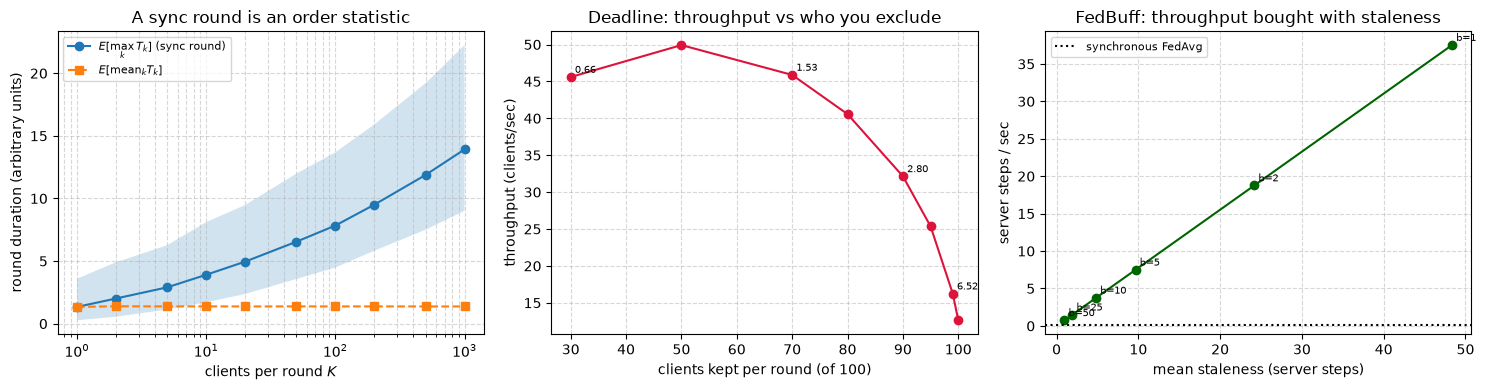

In [34]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.0))

ax[0].semilogx(Ks, [sim[int(k)][0].mean() for k in Ks], "o-", label=r"$E[\max_k T_k]$ (sync round)")
ax[0].semilogx(Ks, [sim[int(k)][1].mean() for k in Ks], "s--", label=r"$E[\mathrm{mean}_k T_k]$")
ax[0].fill_between(Ks, [np.percentile(sim[int(k)][0], 5) for k in Ks],
                   [np.percentile(sim[int(k)][0], 95) for k in Ks], alpha=0.2)
ax[0].set_xlabel("clients per round $K$")
ax[0].set_ylabel("round duration (arbitrary units)")
ax[0].set_title("A sync round is an order statistic")
ax[0].legend(fontsize=8)
ax[0].grid(True, ls="--", alpha=0.5, which="both")

ax[1].plot([r[1] for r in dl_rows], [r[3] for r in dl_rows], "o-", color="crimson")
for dl, kept, rt, thr in dl_rows[::2]:
    ax[1].annotate(f"{dl:.2f}", (kept, thr), fontsize=7, xytext=(3, 3),
                   textcoords="offset points")
ax[1].set_xlabel(f"clients kept per round (of {K_D})")
ax[1].set_ylabel("throughput (clients/sec)")
ax[1].set_title("Deadline: throughput vs who you exclude")
ax[1].grid(True, ls="--", alpha=0.5)

ax[2].plot([r[4] for r in fb_rows], [r[3] for r in fb_rows], "o-", color="darkgreen")
for b, steps, t, thr, ms, p95 in fb_rows:
    ax[2].annotate(f"b={b}", (ms, thr), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[2].axhline((N_UPD // K_CONC) / t_sync, color="k", ls=":", label="synchronous FedAvg")
ax[2].set_xlabel("mean staleness (server steps)")
ax[2].set_ylabel("server steps / sec")
ax[2].set_title("FedBuff: throughput bought with staleness")
ax[2].legend(fontsize=8)
ax[2].grid(True, ls="--", alpha=0.5)

plt.tight_layout()
print("All three panels are SIMULATED client times (LogNormal), not measurements.")
print("The shape of each argument transfers; the numbers do not.")

> **Observe:** none of these trade-offs is about bytes. A small payload is not the same as a
> fast system.
>
> - **A sync round is a max.** Same work per client, yet the round is **10×** slower at
>   $K=1000$ than at $K=1$. Note the tension with §6: fewer clients per round hurts the
>   estimator but helps the clock.
> - **A deadline is a fairness knob.** The best deadline gives **4×** the throughput of waiting
>   for everyone, but it drops **half** the clients every round, and always the slow ones.
>   Their data is then underrepresented. Week 14 turns this into a measurable requirement.
> - **FedBuff trades staleness for throughput.** Smaller buffers give more server steps per
>   second and more staleness. This is Week 7's staleness curve seen from the other side.


---

## 8. The same thing under Flower

So far we have used our own harness: a loop over clients and a `(K, D)` matrix. It is fast,
exact, and deterministic. Stage 4 moved this code to **Flower**, so we check that compressed
FedAvg works with the real framework's aggregation.

We call Flower's **strategy API directly**: build `FitRes` objects by hand and call
`FedAvg.aggregate_fit`. This runs Flower's real aggregation and its real
`ndarrays_to_parameters` boundary, with no Ray and no nondeterminism.

**Why not `run_simulation`?** It runs each client in a **Ray worker** and ships `client_fn`
there with `cloudpickle`. An `eqx.Module` subclass **defined in a notebook** does not survive
the trip: it loses its PyTree registration, which shows up as errors like
`FrozenInstanceError: cannot assign to field 'conv1'`. There are two fixes: put the model in an
**importable `.py` module** (which a `flwr run` project gives you), or build it from
`eqx.nn.Sequential` of library layers (Week 9).

> **The notebook teaches the aggregation math with the strategy API. The real Lab 8 runs
> `flwr run` on the GPU node.**

Two points below: the **byte counter rides in the metrics dict** (Weeks 12–13 reuse this hook),
and **the server is unmodified**. A client that returns $\theta^{(r)} + \mathcal{C}(\Delta_k)$
turns stock `FedAvg` into compressed FedAvg.


In [35]:
from flwr.server.strategy import FedAvg
from flwr.server.client_proxy import ClientProxy
from flwr.common import (ndarrays_to_parameters, parameters_to_ndarrays,
                         FitRes, Status, Code)

class SimProxy(ClientProxy):
    # Minimal ClientProxy: the strategy only reads `cid`. No Ray, no processes.
    def __init__(self, cid): super().__init__(cid)
    def get_properties(self, *a, **k): pass
    def get_parameters(self, *a, **k): pass
    def fit(self, *a, **k): pass
    def evaluate(self, *a, **k): pass
    def reconnect(self, *a, **k): pass


UPLINK_LOG = []

class ByteCountingFedAvg(FedAvg):
    # The standard hook: subclass FedAvg, override aggregate_fit, record.
    # Weeks 12-13 use this same seam for DP accounting and Byzantine filtering.
    def aggregate_fit(self, rnd, results, failures):
        params, metrics = super().aggregate_fit(rnd, results, failures)
        UPLINK_LOG.append({
            "round": rnd,
            "n_clients": len(results),
            "uplink_bytes": sum(r.metrics["uplink_bytes"] for _, r in results),
            "naive_bytes": sum(r.metrics["naive_bytes"] for _, r in results),
        })
        return params, metrics


def flower_client_fit(theta_flat, pid, shards, tau, rnd, scheme):
    # What a Flower client's fit() does: train locally, compress the Delta, report
    # theta + C(Delta) and the byte count. The SERVER is stock FedAvg.
    sp = unravel(jnp.asarray(theta_flat))
    K = len(shards)
    wp, wb, wo = broadcast(sp, K), broadcast(bn0, K), broadcast(opt0, K)
    xs, ys = sample_batches(shards, tau, rnd)
    cp, _, _ = run_clients(wp, wb, wo, xs, ys)
    theta_k = flatten_clients(jax.tree.map(lambda c: c, cp))[pid]
    delta = theta_k - jnp.asarray(theta_flat)
    ghat = scheme.fn(delta, jax.random.fold_in(jax.random.key(11), rnd * K + pid))
    idx = np.asarray(jnp.argsort(jnp.abs(delta))[-max(1, int(D_PARAMS * 0.1)):])
    nb = scheme.nbytes(D_PARAMS, idx)
    return np.asarray(jnp.asarray(theta_flat) + ghat), float(nb)


print("Flower client boundary: JAX PyTree --ravel_pytree--> flat vector --np.asarray--> ndarray")
print("                        and back. The treedef stays on the side.")
print("The compression lives entirely in the CLIENT. The server is unmodified FedAvg.")

Flower client boundary: JAX PyTree --ravel_pytree--> flat vector --np.asarray--> ndarray
                        and back. The treedef stays on the side.
The compression lives entirely in the CLIENT. The server is unmodified FedAvg.


In [36]:
# Drive real Flower aggregation for a few rounds with 8-bit quantized uplinks.
SCHEME_FL = scheme_quant(8, stochastic=True)
R_FL, K_FL = 5, K_CLIENTS
sizes_fl = np.array([len(s) for s in shards_nid], dtype=np.float64)

strategy = ByteCountingFedAvg(fraction_fit=1.0, min_fit_clients=K_FL,
                              min_available_clients=K_FL, fraction_evaluate=0.0)
theta = np.asarray(flat0)
UPLINK_LOG.clear()

print(f"Flower FedAvg.aggregate_fit, {R_FL} rounds, {K_FL} clients, uplink = {SCHEME_FL.name}")
print(f"{'round':>6}  {'clients':>8}  {'uplink kB':>10}  {'naive kB':>9}  {'test acc':>9}")
print("-" * 50)
t0 = time.perf_counter()
for r in range(R_FL):
    results = []
    for pid in range(K_FL):
        w_new, nb = flower_client_fit(theta, pid, shards_nid, TAU, r, SCHEME_FL)
        results.append((SimProxy(str(pid)),
                        FitRes(status=Status(Code.OK, ""),
                               parameters=ndarrays_to_parameters([w_new]),
                               num_examples=int(sizes_fl[pid]),
                               metrics={"uplink_bytes": nb, "naive_bytes": bytes_dense(D_PARAMS)})))
    agg, _ = strategy.aggregate_fit(r + 1, results, [])
    theta = parameters_to_ndarrays(agg)[0]
    _, a = evaluate(unravel(jnp.asarray(theta)), bn0, X_te, Y_te)
    lg = UPLINK_LOG[-1]
    print(f"{r + 1:>6}  {lg['n_clients']:>8}  {lg['uplink_bytes'] / 1e3:>10.2f}  "
          f"{lg['naive_bytes'] / 1e3:>9.2f}  {float(a):>9.3f}")

tot_u = sum(l["uplink_bytes"] for l in UPLINK_LOG)
tot_n = sum(l["naive_bytes"] for l in UPLINK_LOG)
print(f"\ntotal federation uplink: {tot_u / 1e3:.1f} kB vs {tot_n / 1e3:.1f} kB dense "
      f"-> {tot_n / tot_u:.1f}x   ({time.perf_counter() - t0:.1f}s)")

Flower FedAvg.aggregate_fit, 5 rounds, 5 clients, uplink = 8-bit quant (stoch)
 round   clients   uplink kB   naive kB   test acc
--------------------------------------------------


     1         5        4.34      17.20      0.274


     2         5        4.34      17.20      0.353


     3         5        4.34      17.20      0.382


     4         5        4.34      17.20      0.409


     5         5        4.34      17.20      0.315

total federation uplink: 21.7 kB vs 86.0 kB dense -> 4.0x   (2.1s)


In [37]:
# Does Flower's aggregation agree with our direct harness? It must, exactly.
# Flower weights by num_examples; our harness weights by n_k. Same weights -> same answer.
theta_chk = np.asarray(flat0)
sent_rows = []
for pid in range(K_FL):
    w_new, _ = flower_client_fit(theta_chk, pid, shards_nid, TAU, 0, scheme_dense())
    sent_rows.append(w_new)

w_ours = sizes_fl / sizes_fl.sum()
ours = np.asarray(w_ours, dtype=np.float32) @ np.stack(sent_rows)

strat_chk = FedAvg(fraction_fit=1.0, min_fit_clients=K_FL, min_available_clients=K_FL)
res_chk = [(SimProxy(str(p)), FitRes(status=Status(Code.OK, ""),
            parameters=ndarrays_to_parameters([sent_rows[p]]),
            num_examples=int(sizes_fl[p]), metrics={}))
           for p in range(K_FL)]
theirs = parameters_to_ndarrays(strat_chk.aggregate_fit(1, res_chk, [])[0])[0]

d_agg = float(np.max(np.abs(ours - theirs)))
print("our direct harness   vs   flwr FedAvg.aggregate_fit  (same round, same weights)")
print("-" * 68)
print(f"  max |difference| : {d_agg:.3e}")
print(f"  identical        : {d_agg < 1e-5}")
print(f"  n_k              : {sizes_fl.astype(int)}  -> weights {np.round(w_ours, 4)}")
print()
print("So the sweeps in Sections 5-6 and 9 (direct harness, for speed and determinism)")
print("compute exactly what Flower would. That justifies the fast harness for the Pareto")
print("plot: checked, not assumed.")

our direct harness   vs   flwr FedAvg.aggregate_fit  (same round, same weights)
--------------------------------------------------------------------
  max |difference| : 1.192e-07
  identical        : True
  n_k              : [ 137  868 1487 1558   46]  -> weights [0.0334 0.2119 0.363  0.3804 0.0112]

So the sweeps in Sections 5-6 and 9 (direct harness, for speed and determinism)
compute exactly what Flower would. That justifies the fast harness for the Pareto
plot: checked, not assumed.


> **Observe:**
>
> - **The server needed no changes.** Stock `FedAvg` plus a client that returns
>   $\theta^{(r)} + \mathcal{C}(\Delta_k)$ *is* compressed FedAvg, because averaging parameters
>   is the Δ-form (Week 7). Compression is a **client-side** concern, so different clients can
>   even use different compressors.
> - **We verified that the fast harness matches Flower.** They agree to $1.2\times10^{-7}$
>   (float32 precision) on the same round. That justifies running §9's sweep without Ray.
> - (The `No fit_metrics_aggregation_fn provided` warning is harmless. We read the metrics in
>   our own strategy subclass.)


---

## 9. Lab 8: the accuracy-vs-bytes Pareto frontier

The question to answer:

> **For a given uplink budget, what is the best accuracy, and which scheme gets it?**

Plot accuracy against cumulative bytes per client, one point per scheme. A scheme is
**dominated** if another reaches at least its accuracy for no more bytes. Naming the dominated
schemes is most of the plot's value.

The x-axis uses §2's full accounting: values, indices, metadata, and the uncompressed batch
statistics.

Two schemes are included as **expected failures**:

- **1-bit quantization:** §3 showed the error model breaks at $b=1$.
- **random-$k$ at $d=0.1$:** unbiased, but its variance is $\frac{1-d}{d}\lVert v\rVert^2 =
  9\lVert v\rVert^2$ (Exercise 2).

**Write down your predictions for these two first.** One of them will surprise you.


In [38]:
pareto_schemes = [
    scheme_dense(),
    scheme_quant(8, stochastic=True),
    scheme_quant(4, stochastic=True),
    scheme_quant(2, stochastic=True),
    scheme_quant(1, stochastic=True),                       # expected failure
    scheme_topk(0.10),
    scheme_topk(0.10, ef=True),
    scheme_topk(0.01),
    scheme_topk(0.01, ef=True),
    scheme_topk(0.10, ef=True, bits=8, index="bitmap"),     # the composition
    scheme_randk(0.10),                                     # expected failure
]

print(f"Lab 8 sweep: {len(pareto_schemes)} schemes x {ROUNDS} rounds, tau={TAU}, "
      f"Dirichlet alpha={ALPHA}, K={K_CLIENTS}")
print(f"{'scheme':>34}  {'B/rnd':>8}  {'ratio':>7}  {'kB total':>9}  {'acc':>7}  {'loss':>8}")
print("-" * 80)
pareto = []
t0 = time.perf_counter()
for sch in pareto_schemes:
    h = run_fl(ROUNDS, TAU, shards_nid, sch)
    per_round = sch.nbytes(D_PARAMS, idx10) + 4.0 * BN_VALUES
    pareto.append((sch, h, per_round))
    print(f"{sch.name:>34}  {per_round:>8.0f}  {(PARAM_BYTES + 4.0 * BN_VALUES) / per_round:>6.1f}x  "
          f"{h[-1]['bytes'] / 1e3:>9.2f}  {h[-1]['acc']:>7.3f}  {h[-1]['loss']:>8.4f}")
print(f"\n({time.perf_counter() - t0:.1f}s on {jax.devices()[0].device_kind}. "
      f"Bytes are EXACT; accuracies are this toy problem's.)")

Lab 8 sweep: 11 schemes x 24 rounds, tau=8, Dirichlet alpha=0.5, K=5
                            scheme     B/rnd    ratio   kB total      acc      loss
--------------------------------------------------------------------------------


                     dense float32      3576     1.0x      85.82    0.845    0.8389


               8-bit quant (stoch)      1004     3.6x      24.10    0.845    0.8391


               4-bit quant (stoch)       574     6.2x      13.78    0.834    0.8392


               2-bit quant (stoch)       359    10.0x       8.62    0.627    1.1237


               1-bit quant (stoch)       252    14.2x       6.04    0.271    1.3743


... (2 outputs left out)

                      top-k d=0.01       208    17.2x       4.99    0.301    1.3752


                 top-k d=0.01 + EF       208    17.2x       4.99    0.381    1.3560


          top-k d=0.1 + 8-bit + EF       338    10.6x       8.10    0.837    0.9148


           rand-k d=0.1 (unbiased)       824     4.3x      19.78    0.674    0.8117

(25.2s on cpu. Bytes are EXACT; accuracies are this toy problem's.)


In [39]:
# Identify the Pareto frontier: a scheme is dominated if another reaches >= its accuracy
# for <= its bytes. Operate on the FINAL (bytes, accuracy) point of each run.
pts = [(s.name, h[-1]["bytes"], h[-1]["acc"]) for s, h, _ in pareto]

def is_dominated(i, pts, tol=0.0):
    _, bi, ai = pts[i]
    for j, (_, bj, aj) in enumerate(pts):
        if j != i and bj <= bi and aj >= ai + tol and (bj < bi or aj > ai):
            return True, pts[j][0]
    return False, None

print(f"Pareto analysis at {ROUNDS} rounds. Dominated = another scheme is at least as")
print(f"accurate for no more bytes.")
print(f"{'scheme':>34}  {'kB':>8}  {'acc':>7}  {'status':>12}  {'dominated by':>28}")
print("-" * 96)
frontier = []
for i, (nm, b, a) in enumerate(pts):
    dom, by = is_dominated(i, pts)
    if not dom:
        frontier.append((nm, b, a))
    print(f"{nm:>34}  {b / 1e3:>8.2f}  {a:>7.3f}  {'DOMINATED' if dom else 'on frontier':>12}  "
          f"{(by or '--'):>28}")

print(f"\nON THE FRONTIER ({len(frontier)} of {len(pts)}):")
for nm, b, a in sorted(frontier, key=lambda x: x[1]):
    print(f"   {b / 1e3:>8.2f} kB  ->  acc {a:.3f}   {nm}")

Pareto analysis at 24 rounds. Dominated = another scheme is at least as
accurate for no more bytes.
                            scheme        kB      acc        status                  dominated by
------------------------------------------------------------------------------------------------
                     dense float32     85.82    0.845     DOMINATED           8-bit quant (stoch)
               8-bit quant (stoch)     24.10    0.845   on frontier                            --
               4-bit quant (stoch)     13.78    0.834     DOMINATED      top-k d=0.1 + 8-bit + EF
               2-bit quant (stoch)      8.62    0.627     DOMINATED      top-k d=0.1 + 8-bit + EF
               1-bit quant (stoch)      6.04    0.271     DOMINATED                  top-k d=0.01
                       top-k d=0.1     19.78    0.619     DOMINATED           4-bit quant (stoch)
                  top-k d=0.1 + EF     19.78    0.840   on frontier                            --
                   

dense float32               :   85.82 kB  acc 0.845
cheapest within 2% of dense :    8.10 kB  acc 0.837  -> 10.6x fewer bytes
   scheme: top-k d=0.1 + 8-bit + EF


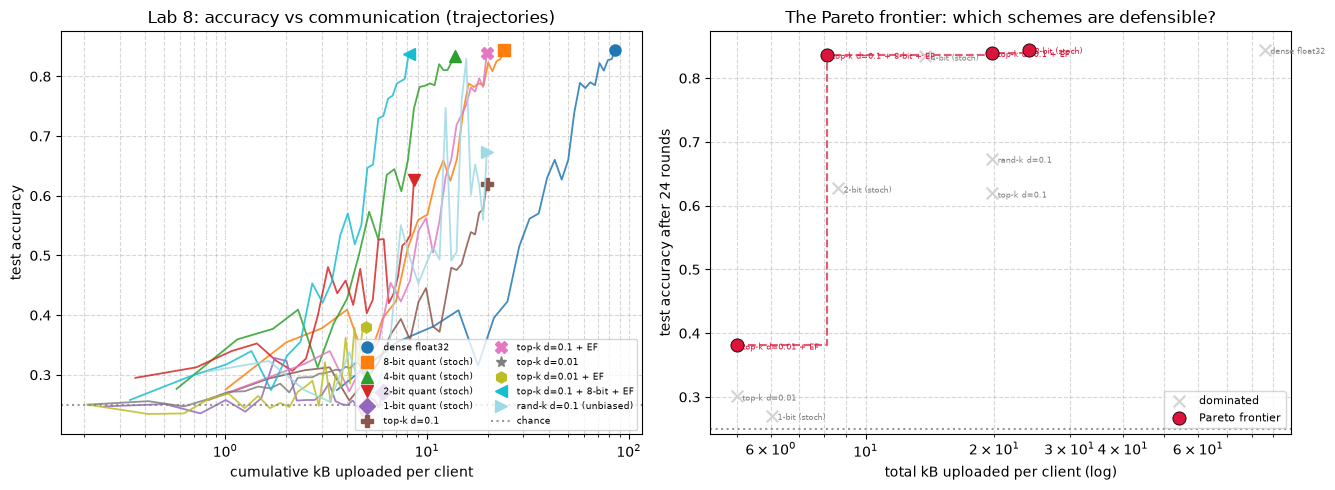

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(13.5, 5.0))

markers = ["o", "s", "^", "v", "D", "P", "X", "*", "h", "<", ">", "p"]
cmap = plt.cm.tab20(np.linspace(0, 1, len(pareto)))

# --- left: full trajectories (accuracy vs cumulative bytes)
for (s, h, _), c, mk in zip(pareto, cmap, markers):
    ax[0].semilogx([d["bytes"] / 1e3 for d in h], [d["acc"] for d in h], "-", color=c, lw=1.3,
                   alpha=0.85)
    ax[0].semilogx([h[-1]["bytes"] / 1e3], [h[-1]["acc"]], mk, color=c, ms=8, label=s.name)
ax[0].axhline(1 / N_CLASSES, color="gray", ls=":", alpha=0.8, label="chance")
ax[0].set_xlabel("cumulative kB uploaded per client")
ax[0].set_ylabel("test accuracy")
ax[0].set_title("Lab 8: accuracy vs communication (trajectories)")
ax[0].legend(fontsize=6.5, loc="lower right", ncol=2)
ax[0].grid(True, ls="--", alpha=0.5, which="both")

# --- right: the frontier itself, at the final round
fx = np.array([p[1] / 1e3 for p in pts])
fy = np.array([p[2] for p in pts])
on = np.array([not is_dominated(i, pts)[0] for i in range(len(pts))])

ax[1].scatter(fx[~on], fy[~on], c="lightgray", s=70, marker="x", label="dominated", zorder=3)
ax[1].scatter(fx[on], fy[on], c="crimson", s=90, marker="o", label="Pareto frontier", zorder=4,
              edgecolors="k", linewidths=0.6)
fr = sorted([(p[1] / 1e3, p[2]) for i, p in enumerate(pts) if on[i]])
# staircase envelope
sx, sy, best = [], [], -1.0
for b, a in fr:
    if a > best:
        sx.append(b); sy.append(a); best = a
ax[1].step(sx, sy, where="post", color="crimson", ls="--", alpha=0.7, zorder=2)
for i, (nm, b, a) in enumerate(pts):
    ax[1].annotate(nm.replace(" (unbiased)", "").replace(" quant", ""), (b / 1e3, a),
                   fontsize=6, xytext=(4, -3), textcoords="offset points",
                   color=("crimson" if on[i] else "gray"))
ax[1].set_xscale("log")
ax[1].set_xlabel("total kB uploaded per client (log)")
ax[1].set_ylabel(f"test accuracy after {ROUNDS} rounds")
ax[1].set_title("The Pareto frontier: which schemes are defensible?")
ax[1].axhline(1 / N_CLASSES, color="gray", ls=":", alpha=0.8)
ax[1].legend(fontsize=8, loc="lower right")
ax[1].grid(True, ls="--", alpha=0.5, which="both")

plt.tight_layout()

dense_pt = [p for p in pts if p[0] == "dense float32"][0]
best_cheap = min([p for p in pts if p[2] >= dense_pt[2] - 0.02], key=lambda p: p[1])
print(f"dense float32               : {dense_pt[1] / 1e3:>7.2f} kB  acc {dense_pt[2]:.3f}")
print(f"cheapest within 2% of dense : {best_cheap[1] / 1e3:>7.2f} kB  acc {best_cheap[2]:.3f}  "
      f"-> {dense_pt[1] / best_cheap[1]:.1f}x fewer bytes")
print(f"   scheme: {best_cheap[0]}")

> **Observe — the Lab 8 deliverable.** Only **4 of 11** schemes are on the frontier.
>
> - **Dense float32 is dominated.** 8-bit stochastic quantization gets the same accuracy
>   (**0.845 vs 0.845**) with **3.6× fewer bytes**. Uncompressed FedAvg is not a safe default.
>   It pays 3.6× for nothing.
> - **The combined scheme** (top-$k$ + EF + 8-bit + bitmap) reaches **0.837 at 8.10 kB**:
>   **10.6× fewer bytes than dense for 0.8 accuracy points.** Every part matters: top-$k$
>   picks the coordinates (§4), EF repays the rest (§5; without it, 0.619), 8-bit shrinks the
>   values (§3), and the bitmap keeps the indices cheap (§2).
> - **The prediction that failed.** Random-$k$ was meant to lose, but it scores **0.674** and
>   **beats plain top-$k$ (0.619)** at equal bytes. Over 24 rounds random-$k$'s noise averages
>   out, while top-$k$'s bias adds up. With EF, top-$k$ wins clearly (0.840). The ranking is
>   **top-$k$+EF > random-$k$ > top-$k$**, so our §4 framing was too simple. Both random-$k$
>   and plain top-$k$ are dominated by 4-bit quantization, which is more accurate *and* 30%
>   cheaper.
> - **1-bit failed as predicted** (**0.271**, about chance).
>
> **Caveats.**
> 1. **Single seed, toy problem, 24 rounds.** Differences under ~2 points are noise. Dense,
>    8-bit, 4-bit, top-$k$+EF, and the combined scheme (0.834–0.845) form a *cluster*, so read
>    "on the frontier" as *"not ruled out"*. The robust claims are the big ones: 1-bit fails,
>    EF at $d=0.1$ is worth +0.22, and dense is dominated. Further Exercise 1 adds error bars.
> 2. **The x-axis is exact and the y-axis is not.** Bytes transfer to CIFAR-10 and to BERT,
>    but the accuracies come from an 860-parameter toy. **Trust x; re-measure y.**
> 3. **Full participation, 5 clients.** In Exercise 3, EF's benefit at $d=0.01$ disappeared at
>    $C=0.4$. With 100 clients and $C = 0.1$, the three EF points (3 of the 4 on the frontier)
>    may move down or off. A frontier depends on the deployment.


### 🔬 Exercise 4

**Combine the two factors.** Week 7 divided *how often* by $\tau$, and Week 10 divides *how
much* by a compression ratio:

$$\text{total bytes} \;=\; \frac{T}{\tau} \times \big|\mathcal{C}(\Delta)\big|$$

So the byte savings multiply. But larger $\tau$ adds **client drift**, and compression adds
**error**. Do the two interact in accuracy?

Sweep $\tau \in \{4, 8, 16\}$ × {dense, 8-bit stochastic, top-$k$ $d=0.1$+EF} at a **fixed
local-step budget** (same compute in every cell). Report (bytes, accuracy) and answer: is the
accuracy cost of compression the same at every $\tau$?


In [41]:
# --- Reference solution (instructor: blank this out for students) ---

T_BUDGET = 96                        # total local steps per client -- FIXED across the grid
taus_x = [4, 8, 16]
schemes_x = [("dense", scheme_dense()),
             ("8-bit stoch", scheme_quant(8, stochastic=True)),
             ("top-k 0.1 + EF", scheme_topk(0.10, ef=True))]

print(f"fixed budget: {T_BUDGET} local steps per client in EVERY cell (identical compute)")
print(f"{'tau':>5}  {'rounds':>7}  {'scheme':>16}  {'kB/client':>10}  {'acc':>7}  "
      f"{'acc vs dense':>13}")
print("-" * 68)
grid = {}
t0 = time.perf_counter()
for tau_x in taus_x:
    R_x = T_BUDGET // tau_x
    for nm, sch in schemes_x:
        h = run_fl(R_x, tau_x, shards_nid, sch, seed=3)
        grid[(tau_x, nm)] = h
        base = grid[(tau_x, "dense")][-1]["acc"]
        print(f"{tau_x:>5}  {R_x:>7}  {nm:>16}  {h[-1]['bytes'] / 1e3:>10.2f}  "
              f"{h[-1]['acc']:>7.3f}  {h[-1]['acc'] - base:>+13.3f}")
print(f"\n({time.perf_counter() - t0:.1f}s)")

print(f"\nDo the byte savings MULTIPLY? (bytes relative to tau=4 dense)")
print(f"{'':>16}" + "".join(f"{'tau=' + str(t):>12}" for t in taus_x))
print("-" * 54)
ref = grid[(4, "dense")][-1]["bytes"]
for nm, _ in schemes_x:
    print(f"{nm:>16}" + "".join(f"{ref / grid[(t, nm)][-1]['bytes']:>11.1f}x" for t in taus_x))
print()
print("The byte columns multiply EXACTLY, as they must: bytes = (T/tau) x |C(Delta)| is a")
print("product of two independent factors. That is arithmetic, not a finding.")
print()
print(f"The real question is ACCURACY. Compression cost at each tau:")
for tau_x in taus_x:
    base = grid[(tau_x, "dense")][-1]["acc"]
    q = grid[(tau_x, "8-bit stoch")][-1]["acc"] - base
    t_ = grid[(tau_x, "top-k 0.1 + EF")][-1]["acc"] - base
    print(f"  tau={tau_x:>2}: 8-bit {q:+.3f}   top-k+EF {t_:+.3f}")
print()
print("The two schemes behave DIFFERENTLY:")
print()
print("  8-bit quantization: penalty ~0 at every tau, so no sign of interaction.")
print("  Quantization error is per-coordinate noise; it ignores how far clients drifted.")
print()
print("  top-k + EF: the penalty GROWS with tau (-0.048 -> -0.098 -> -0.111). A likely")
print("  mechanism: larger tau gives larger, more client-specific Deltas (Week 7's drift),")
print("  so clients agree less on which coordinates matter, and per-client top-k keeps less")
print("  of what the AVERAGE needs. EF repays the rest over rounds, and larger tau means")
print("  FEWER rounds.")
print()
print("  But: one seed, three points. This is a HYPOTHESIS, not a result. To test it, use")
print("  more seeds and check whether the clients' top-k SUPPORTS overlap less as tau grows.")

fixed budget: 96 local steps per client in EVERY cell (identical compute)
  tau   rounds            scheme   kB/client      acc   acc vs dense
--------------------------------------------------------------------


    4       24             dense       85.82    0.661         +0.000


    4       24       8-bit stoch       24.10    0.665         +0.004


    4       24    top-k 0.1 + EF       19.78    0.613         -0.048


    8       12             dense       42.91    0.660         +0.000


    8       12       8-bit stoch       12.05    0.661         +0.001


    8       12    top-k 0.1 + EF        9.89    0.562         -0.098


   16        6             dense       21.46    0.668         +0.000


   16        6       8-bit stoch        6.02    0.669         +0.001


   16        6    top-k 0.1 + EF        4.94    0.557         -0.111

(12.7s)

Do the byte savings MULTIPLY? (bytes relative to tau=4 dense)
                       tau=4       tau=8      tau=16
------------------------------------------------------
           dense        1.0x        2.0x        4.0x
     8-bit stoch        3.6x        7.1x       14.2x
  top-k 0.1 + EF        4.3x        8.7x       17.4x

The byte columns multiply EXACTLY, as they must: bytes = (T/tau) x |C(Delta)| is a
product of two independent factors. That is arithmetic, not a finding.

The real question is ACCURACY. Compression cost at each tau:
  tau= 4: 8-bit +0.004   top-k+EF -0.048
  tau= 8: 8-bit +0.001   top-k+EF -0.098
  tau=16: 8-bit +0.001   top-k+EF -0.111

The two schemes behave DIFFERENTLY:

  8-bit quantization: penalty ~0 at every tau, so no sign of interaction.
  Quantization error is per-coordinate noise; it ignores how far clients drifted.

  top-k + EF: the penalty GROWS with tau (-0.048 -> -0.09

---

## Summary

$$\text{bytes} = \underbrace{\frac{T}{\tau}}_{\text{Week 7}} \times
\underbrace{\big|\mathcal{C}(\Delta)\big|}_{\text{Week 10}}$$

- **Count honestly first.** Sparse = (index, value) pairs, so naive top-$k$ at $d=0.1$ saves
  **5×, not 10×**. Quantization needs metadata. A **bitmap** ($D/8$) wins above $d=1/32$,
  **varint** gaps win below, and $\log_2\binom{D}{k}$ is the floor.
- **Quantization:** $\frac{R^2}{12(2^b-1)^2}$ is exact on uniform data, and on Gaussian data
  from $b \ge 4$. On the real $\Delta$ it is off by up to ~8× because of **heavy tails**, not
  small $D$ (the same-size Gaussian control obeys it). At $b=1$ it breaks the other way.
  **For real updates, measure.**
- **Stochastic rounding is unbiased.** As clients are added, the deterministic error stays
  flat while the stochastic error shrinks like $1/\sqrt{KD}$. The cost is ~1.7× the MSE.
- **Sparsification, with a control.** The top 10% of the real $\Delta$ holds 99.3% of its
  energy, but Gaussian noise already holds 44.7%. The real advantage over the control grows
  from $2.2\times$ at $d=0.1$ to $13\times$ at $d=0.001$.
- **Error feedback** (three lines): top-$k$ at $d=0.1$ goes from 0.619 to **0.840** (dense
  0.845) at identical bytes. At $d=0.01$ it recovers only ~15% of the gap, because the debt
  grows faster than it can be repaid. EF turns bias into **delay**, which only helps if the
  delay fits your round budget.
- **Statefulness sets the design rule.** Cross-silo → top-$k$ + EF. Cross-device (clients seen
  once) → **unbiased, stateless** compressors (QSGD, random-$k$), which are corrected by
  averaging across clients instead of across rounds. This matches SCAFFOLD vs FedProx in
  Week 9.
- **Client sampling:** FedAvg's $n_k/\sum_{j\in S} n_j$ weights are a biased ratio estimator.
  Size-proportional sampling + uniform averaging is unbiased. Non-IID data makes sampling far
  noisier.
- **Stragglers:** a sync round is $\max_k T_k$, which grows with $K$. Deadlines raise
  throughput but drop the slow devices (a fairness issue). FedBuff trades staleness for
  throughput.
- **Lab 8 frontier: 4 of 11 schemes survive, and dense is not one of them.** 8-bit matches
  dense at 3.6× fewer bytes. The combined scheme is 10.6× cheaper for 0.8 points. Our
  prediction failed: random-$k$ (0.674) beat plain top-$k$ (0.619), and top-$k$+EF (0.840)
  beat both.
- **Trust the x-axis (exact bytes); re-measure the y-axis (toy accuracy)** on the GPU node.

**Next.** Week 11 attacks non-IID directly with personalization (Ditto, FedBN). Week 12 asks
whether $\Delta_k$ is **safe to send**. Top-$k$ sends the most informative coordinates, which
is what a gradient-inversion attack wants. **Compression is not privacy.** Week 15 shrinks $D$
itself with LoRA, which (Exercise 1) beats every constant factor here.

### Reading

- **Course textbook, Ch. 6**, *Federated Learning: From Theory to Practice*
  ([arXiv:2505.19183](https://arxiv.org/abs/2505.19183)). Check every ratio it quotes for the
  index cost.
- **Alistarh et al. (2017), "QSGD"** ([arXiv:1610.02132](https://arxiv.org/abs/1610.02132)):
  stochastic quantization, plus encoding (§2's lesson).
- **Karimireddy et al. (2019), "Error Feedback Fixes SignSGD..."**
  ([arXiv:1901.09847](https://arxiv.org/abs/1901.09847)) and **Stich et al. (2018),
  "Sparsified SGD with Memory"** ([arXiv:1809.07599](https://arxiv.org/abs/1809.07599)): the
  theory behind §5. Compare their contraction assumption with Exercise 2.
- **Lin et al. (2018), "Deep Gradient Compression"**
  ([arXiv:1712.01887](https://arxiv.org/abs/1712.01887)): top-$k$ at $d = 0.001$ in practice.
- **Bernstein et al. (2018), "signSGD"** ([arXiv:1802.04434](https://arxiv.org/abs/1802.04434)):
  the $b=1$ case.
- **Nguyen et al. (2022), "FedBuff"** ([arXiv:2106.06639](https://arxiv.org/abs/2106.06639)):
  §7's third panel.
- Optional: **Konečný et al. (2016)** ([arXiv:1610.05492](https://arxiv.org/abs/1610.05492)):
  the original statement of the problem.

### Further Exercises

1. **Error bars on the Pareto plot.** Rerun §9 over 5 seeds and redo the domination table.
   Which "dominated" verdicts survive?
2. **Map EF's benefit across density.** We measured only $d=0.1$ (+0.22) and $d=0.01$
   (+0.08). Sweep $d$ from 0.005 to 0.3 and find where the benefit peaks. Does the peak relate
   to §4's energy curve?
3. **Per-layer quantization.** Use one $(\ell, s)$ per layer or block, **count the extra 8
   bytes per block**, and see whether the accuracy gain beats the byte cost.
4. **Compression meets privacy.** Does top-$k$ help privacy (less is sent) or hurt it (only
   the most informative coordinates are sent)? Write a hypothesis now and test it in Week 12
   with DLG, against top-$k$ and random-$k$.
5. **Real bytes on a real wire.** Implement real bit-packing and varint, serialize a payload,
   and compare `len(buf)` with the byte model. Then add Flower's protobuf/gRPC overhead: at
   what payload size does it stop being negligible?
6. **Reproduce Deep Gradient Compression** at $d = 0.001$ on top of §5's EF, ablate its four
   ingredients, and recompute its headline ratio with §2's index accounting.
